# Milestone 3 : Construire le moteur de consolidation

## Section 0 : Ce que nous construisons

Au milestone 2, nous avons mesuré notre situation : nos livraisons coûtent
**143 422 €** sur le périmètre que nous optimisons, parce que nos camions partent
presque vides. Ici, nous construisons le **moteur** qui corrige cela.

Notre moteur fait trois choses, simplement :

1. pour chaque couple **fournisseur x usine**, il choisit **un profil de livraison
   stable** (le même rythme sur tout l'horizon) ;
2. il **regroupe** les besoins dans des camions bien remplis, à raison d'**un seul
   camion par couple et par jour** (H19) ;
3. il **chiffre l'économie** par rapport à notre baseline.

Trois règles nouvelles encadrent ce milestone :

- **H19** (notre choix) : un fournisseur livre une usine avec **au plus un camion
  par jour** (24 500 kg et 110,4 m³ au plus). **Une ligne n'est jamais coupée.**
- **H20** (proposition du professeur) : une ligne plus lourde qu'un camion est un
  **envoi exceptionnel**, traité à part. Nous l'appliquons **aussi à la situation
  actuelle** pour comparer à règles égales.
- **H21** (à valider avec le professeur) : un profil est un **maximum**. Nous pouvons
  **ne pas livrer** un jour du profil si c'est moins cher ; ses lignes partent alors
  plus tôt (toujours à 7 jours au plus, R1).

Pour évaluer un profil, nous remplaçons l'affectation simple du milestone 2 par une
**programmation dynamique** (section 4), qui trouve le meilleur choix de jours sous
ces règles. Tout le moteur tourne en **moins de 90 secondes** (section Performance).

Nous travaillons sur notre périmètre (lignes `optimise`, H15). Les lignes
`non optimise : info manquante` restent livrées comme aujourd'hui (H16, un camion
plein chacune, **35 032 €** au pire cas) : identiques avant et après, elles ne
changent pas l'économie.

In [1]:
# Nos outils repris du milestone 2, et le precalcul des prix (searchsorted).
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import time
from itertools import combinations
from collections import defaultdict, Counter

CHEMIN_PLANNING = "../data/processed/planning_propre.csv"
CHEMIN_GRILLE = "../data/processed/grille_prix.csv"
CAP_POIDS = 24500.0      # kg par camion (R2)
CAP_VOLUME = 110.4       # m3 par camion (R2)
TRANCHES_KG = [50, 100, 200, 300, 400, 500, 750, 1000, 1500, 2000, 2500, 3000, 3500, 4000]
JOURS = {0: "lundi", 1: "mardi", 2: "mercredi", 3: "jeudi", 4: "vendredi"}

planning = pd.read_csv(CHEMIN_PLANNING, parse_dates=["date", "semaine"])
grille = pd.read_csv(CHEMIN_GRILLE, index_col=0)
grille.columns = grille.columns.astype(str)
grille.index = grille.index.astype(str)

# Notre perimetre : les lignes optimisables (H15). ligne_grille en texte entier.
opt = planning[planning["statut"] == "optimise"].copy()
opt["ligne_grille"] = opt["ligne_grille"].apply(lambda x: str(int(float(x))))

# Precalcul : pour chaque ligne de grille, le tableau de ses 15 prix (14 tranches + ">4000").
# np.searchsorted trouve la tranche en un seul appel : le moteur reste rapide.
BORNES = np.array(TRANCHES_KG, dtype=float)
PRIX_LIGNE = {lg: grille.loc[lg].values.astype(float) for lg in grille.index}

def tranche_poids(kg):
    """Colonne de la grille : la tranche de poids juste au-dessus (au-dela de 4000 -> '>4000')."""
    for t in TRANCHES_KG:
        if kg <= t:
            return str(t)
    return ">4000"

def prix_camion(ligne_grille, poids_kg):
    """Prix d'un camion : case (ligne = distance, colonne = tranche de poids), via searchsorted.
    side='left' reproduit tranche_poids : un poids pile sur une borne reste dans sa tranche."""
    col = int(np.searchsorted(BORNES, poids_kg, side="left"))   # 0..14 (14 = '>4000')
    return float(PRIX_LIGNE[str(ligne_grille)][col])

def prix_exceptionnel(ligne_grille):
    """Prix d'un envoi exceptionnel : tarif '>4000' de la ligne de grille (H20)."""
    return float(PRIX_LIGNE[str(ligne_grille)][-1])

print("Perimetre :", len(opt), "lignes,", opt.groupby(["supplier_id", "plant"]).ngroups, "couples")
print("Baseline du milestone 2 a battre : 143 422,43 EUR")

Perimetre : 4252 lignes, 171 couples
Baseline du milestone 2 a battre : 143 422,43 EUR


## Section 1 : Notre problème, posé clairement

**1. Ce que nous décidons.** Pour chaque couple fournisseur x usine, **un seul
profil de livraison** stable, et, pour ce profil, **quels jours nous utilisons
vraiment** (H21).

**2. Ce que nous minimisons (fonction objectif).** Le **coût total de transport**,
somme du prix de chaque camion, lu dans la grille (ligne = distance, colonne = poids) :

$$\text{Coût} = \sum_{\text{couples}} \; \sum_{\text{jours livrés}} \; \text{prix}(\text{ligne\_grille},\ \text{poids du camion})$$

**3. Nos contraintes**, une par ligne :

- **R1** : un besoin est livré le jour même ou **avant**, au plus **7 jours** avant, jamais en retard ;
- **R2** : un camion porte au plus **24 500 kg** et **110,4 m³** ;
- **R3** : un camion ne transporte **qu'un seul couple** fournisseur x usine ;
- **R4** : lissage, les livraisons d'une usine sont **réparties dans la semaine** ;
- **H19** : **au plus un camion par couple et par jour** ; une ligne n'est jamais coupée ;
- **H20** : une ligne plus lourde qu'un camion est un **envoi exceptionnel** (un camion, tarif ">4000") ;
- **H21** : le profil est un **maximum** ; nous pouvons sauter un de ses jours si c'est moins cher ;
- livraisons du **lundi au vendredi**, **aucune livraison la semaine de Noël** (H7), **pas avant** le premier jour de l'horizon.

**4. Pourquoi regrouper fait gagner.** Deux petits envois dans un seul camion coûtent
moins cher que deux camions séparés : le prix monte moins vite que le poids.
Vérifions-le sur la grille, à 50 km.

In [2]:
# Regrouper deux envois contre les livrer separement, a 50 km.
exemples = [(300, 300), (1000, 1000), (2000, 2000), (10000, 10000)]
lignes = []
for a, b in exemples:
    separe = prix_camion("50", a) + prix_camion("50", b)
    regroupe = prix_camion("50", a + b)   # a+b <= 24500 : tient dans un camion
    lignes.append({"envois (kg)": f"{a} + {b}", "2 camions separes": round(separe, 2),
                   "1 camion regroupe": round(regroupe, 2), "economie (EUR)": round(separe - regroupe, 2),
                   "economie (%)": round((separe - regroupe) / separe * 100, 1)})
gain_regroupement = pd.DataFrame(lignes)
display(gain_regroupement)

,envois (kg),2 camions separes,1 camion regroupe,economie (EUR),economie (%)
0,300 + 300,105.90,84.92,20.99,19.8
1,1000 + 1000,205.16,145.73,59.43,29.0
2,2000 + 2000,291.46,206.83,84.63,29.0
3,10000 + 10000,427.83,213.92,213.92,50.0


**Notre constat :** regrouper gagne toujours, et d'autant plus que les envois
sont gros : **19,8 %** pour 300 + 300 kg, **29 %** vers 1 à 2 t, jusqu'à **50 %**
pour 10 + 10 t. C'est la raison d'être de notre moteur.

In [3]:
# H19 : un seul camion par jour. 26 t ne tiennent pas en un camion le meme jour ;
# elles partent sur deux jours (un plein, un petit), ce qui reste bien moins cher que deux moities.
sep = 2 * prix_camion("50", 13000)                              # 26 t en deux camions egaux
plein = prix_camion("50", CAP_POIDS) + prix_camion("50", 26000 - CAP_POIDS)  # 1 plein + le reste, 2 jours
print("26 t a 50 km :")
print("  2 camions de 13 t                :", round(sep, 2), "EUR")
print("  1 camion plein + 1,5 t (2 jours) :", round(plein, 2), "EUR")
print("  economie du remplissage a fond   :", round(sep - plein, 2), "EUR (", round((sep - plein) / sep * 100, 1), "% )")

26 t a 50 km :
  2 camions de 13 t                : 427.83 EUR
  1 camion plein + 1,5 t (2 jours) : 335.66 EUR
  economie du remplissage a fond   : 92.17 EUR ( 21.5 % )


**Notre constat :** pour 26 t, **un camion plein plus un petit** coûte
**335,66 €** contre **427,83 €** en deux camions à moitié pleins, soit **21,5 %**
de moins. Avec H19, nous ne mettons qu'**un camion par jour** : le reste part un
**autre jour** du profil (R1 l'autorise). La leçon reste la même : **remplir chaque
camion au maximum**.

## Section 2 : Nos paramètres

Toutes nos règles réglables sont ici, en un seul endroit. Pour changer une règle,
nous changeons cette cellule, rien d'autre.

In [4]:
AVANCE_MAX = 7                      # R1 : au plus 7 jours d'avance, jamais de retard
SEMAINES_FERMEES = ["2026-12-21"]   # H7 : lundi des semaines sans livraison (Noel)
TOLERANCE_LISSAGE = 0.02            # H17 : pour lisser, on accepte +2 % de cout au plus
UN_CAMION_PAR_JOUR = True           # H19 : au plus un camion par couple et par jour
PROFIL_MAXIMUM = True               # H21 : le profil est un maximum (on peut sauter un jour)
TEMPS_MAX_SECONDES = 90             # budget de temps du moteur complet

parametres = pd.DataFrame({
    "parametre": ["AVANCE_MAX (R1)", "SEMAINES_FERMEES (H7)", "TOLERANCE_LISSAGE (H17)",
                  "CAP_POIDS (R2)", "CAP_VOLUME (R2)", "UN_CAMION_PAR_JOUR (H19)",
                  "PROFIL_MAXIMUM (H21)", "TEMPS_MAX_SECONDES"],
    "valeur": [f"{AVANCE_MAX} jours", ", ".join(SEMAINES_FERMEES), f"{TOLERANCE_LISSAGE:.0%}",
               f"{CAP_POIDS:.0f} kg", f"{CAP_VOLUME} m3", str(UN_CAMION_PAR_JOUR),
               str(PROFIL_MAXIMUM), f"{TEMPS_MAX_SECONDES} s"],
})
display(parametres)

,parametre,valeur
0,AVANCE_MAX (R1),7 jours
1,SEMAINES_FERMEES (H7),2026-12-21
2,TOLERANCE_LISSAGE (H17),2%
3,CAP_POIDS (R2),24500 kg
4,CAP_VOLUME (R2),110.4 m3
5,UN_CAMION_PAR_JOUR (H19),True
6,PROFIL_MAXIMUM (H21),True
7,TEMPS_MAX_SECONDES,90 s


## Section 3 : Nos profils de livraison (élargis, H18)

Un **profil** décrit un rythme de livraison stable : une **période** (toutes les 1 à
4 semaines), une **phase** (quelle semaine du cycle), et des **jours** de livraison
(lundi à vendredi). Il se répète à l'identique sur l'horizon.

Nous ne nous limitons pas aux profils du PDF (1, 2, 3, 5 fois par semaine) : nous
testons aussi *une semaine sur deux* et au-delà (**H18**). Avec H21, ces jours sont un
**maximum** : le moteur peut en utiliser moins. C'est la règle des 7 jours (R1) qui
décide si un profil est possible pour un couple.

In [5]:
def libelle_profil(p):
    """Libelle lisible d'un profil (ex. '2 / semaine : lundi, jeudi')."""
    noms = ", ".join(JOURS[j] for j in sorted(p["jours"]))
    if p["periode"] == 1:
        return f"{len(p['jours'])} / semaine : {noms}"
    return f"1 semaine sur {p['periode']} (semaine {p['phase'] + 1}) : {noms}"

def sous_ensembles(jours, tailles):
    """Toutes les combinaisons de jours des tailles demandees."""
    return [frozenset(c) for k in tailles for c in combinations(jours, k)]

def generer_profils():
    """Construit la liste des profils candidats (periodes 1 a 4, H18)."""
    profils = []
    for d in sous_ensembles([0, 1, 2, 3, 4], range(1, 6)):          # periode 1 : 31 profils
        profils.append({"periode": 1, "phase": 0, "jours": d})
    for periode in (2, 3, 4):                                        # periodes 2,3,4 : 1 ou 2 jours
        for phase in range(periode):
            for d in sous_ensembles([0, 1, 2, 3, 4], [1, 2]):
                profils.append({"periode": periode, "phase": phase, "jours": d})
    for p in profils:
        p["libelle"] = libelle_profil(p)
        p["type"] = "PDF" if (p["periode"] == 1 and len(p["jours"]) in (1, 2, 3, 5)) else "elargi"
    return profils

PROFILS = generer_profils()
nb_pdf = sum(p["type"] == "PDF" for p in PROFILS)
print("Profils candidats :", len(PROFILS), "| du PDF :", nb_pdf, "| elargis :", len(PROFILS) - nb_pdf)

Profils candidats : 166 | du PDF : 26 | elargis : 140


Ensuite nous posons le **calendrier** des jours de livraison possibles : les jours
ouvrés (lundi à vendredi) du premier au dernier besoin, sans la semaine fermée. Pour
chaque profil, nous listons une fois pour toutes ses **dates de livraison**.

In [6]:
d0 = opt["date"].min()
d1 = opt["date"].max()
lundi0 = d0 - pd.Timedelta(int(d0.weekday()), unit="D")   # lundi de la premiere semaine
fermees = set(pd.to_datetime(SEMAINES_FERMEES))

def semaine_fermee(dt):
    """Vrai si la date tombe dans une semaine fermee (H7)."""
    return (dt - pd.Timedelta(int(dt.weekday()), unit="D")) in fermees

jours_ouvres = pd.DatetimeIndex([d for d in pd.date_range(d0, d1, freq="D")
                                 if d.weekday() < 5 and not semaine_fermee(d)])

def dates_profil(p):
    """Les dates de livraison d'un profil sur l'horizon (semaine du cycle modulo la periode)."""
    out = []
    for d in jours_ouvres:
        if d.weekday() in p["jours"]:
            semaine = ((d - pd.Timedelta(int(d.weekday()), unit="D")) - lundi0).days // 7
            if semaine % p["periode"] == p["phase"]:
                out.append(d)
    return np.array(out, dtype="datetime64[D]")

DATES_PROFIL = [dates_profil(p) for p in PROFILS]
print("Jours ouvres de l'horizon :", len(jours_ouvres), "du", d0.date(), "au", d1.date())

Jours ouvres de l'horizon : 30 du 2026-11-09 au 2026-12-18


**Notre constat :** nous obtenons **166 profils candidats** (26 du PDF, 140
élargis) et **30 jours ouvrés** sur l'horizon (6 semaines, du 09/11 au 18/12 ; la
semaine de Noël n'est pas dans l'horizon). Tout est prêt pour l'évaluation.

## Section 4 : Comment nous évaluons un profil pour un couple (programmation dynamique)

C'est le cœur du calcul. Un profil donne des **jours possibles**. Avec H21, ces jours
sont un maximum : nous choisissons **quels jours retenir**. Chaque ligne part au
**dernier jour retenu avant ou égal à son besoin** ; une livraison le jour *d* porte
donc tous les besoins entre *d* et le jour retenu suivant.

**Un petit schéma.** Jours du profil : lun — mar — (lun) — mar. Si nous retenons
seulement les jours marqués d'une croix, chaque besoin « glisse » vers la gauche
jusqu'au jour retenu le plus proche :

```
profil      :  L    M    L    M
retenus     :  X    .    .    X
besoins     : b1   b2   b3   b4
partent le  :  L    L    L    M      (b2, b3 avances sur le lundi retenu, <= 7 jours)
```

**Le calcul**, en quatre temps :

1. **Mettre à part les envois exceptionnels** (H20) : une ligne plus lourde qu'un
   camion part seule, tarif ">4000", le jour du profil le plus proche avant ou égal
   à son besoin (7 jours au plus). Elle ne compte ni dans « un camion par jour », ni
   dans le nombre de livraisons.
2. **Préparer une fois** le poids et le volume par date de besoin (tableaux numpy,
   sommes cumulées).
3. **Programmation dynamique.** `meilleur_cout[j]` = coût minimal pour livrer tous
   les besoins **jusqu'à la veille du jour j**, sachant que le jour *j* est retenu.
   Le passage d'un jour retenu *i* au jour retenu suivant *j* (ou à la fin) est
   possible **seulement si** :
   - tous les besoins entre *i* et *j* sont **au plus 7 jours** après *i* (R1) ;
   - leur **poids** total ≤ 24 500 kg et leur **volume** total ≤ 110,4 m³ (H19) ;
   - aucun besoin ne tombe avant le premier jour retenu.

   Coût du passage = `prix_camion(ligne_grille, poids total)` (0 s'il n'y a aucun
   besoin). Grâce à R1, dès qu'un besoin dépasse les 7 jours nous arrêtons : seuls
   les jours suivants proches sont explorés, le calcul est court.
4. **Retrouver le meilleur choix** en remontant les décisions.

Ce résultat est le **meilleur possible** pour la règle « chaque ligne part au dernier
jour retenu avant son besoin » : la programmation dynamique est **exacte** pour ce
problème.

In [7]:
# Nous preparons chaque couple : besoins normaux tries par date, et lignes exceptionnelles a part (H20).
COUPLES = {}
for (s, pl), g in opt.groupby(["supplier_id", "plant"]):
    g = g.sort_values("date")
    exc = (g["weight"].values > CAP_POIDS) | (g["volume"].values > CAP_VOLUME)
    normal = g[~exc]; excep = g[exc]
    COUPLES[(s, pl)] = {
        "besoins": normal["date"].values.astype("datetime64[D]"),
        "poids": normal["weight"].values.astype(float),
        "volume": normal["volume"].values.astype(float),
        "mat": normal["material"].values, "up": normal["unloading_point"].values,
        "qte": normal["schedule_quantity"].values.astype(float),
        "ligne": g["ligne_grille"].iloc[0], "distance": g["distance"].iloc[0],
        "exc_dates": excep["date"].values.astype("datetime64[D]"),
        "exc_poids": excep["weight"].values.astype(float),
        "exc_vol": excep["volume"].values.astype(float), "exc_mat": excep["material"].values,
        "exc_up": excep["unloading_point"].values, "exc_qte": excep["schedule_quantity"].values.astype(float),
        "df": g}

# Couples dont un meme jour de besoin depasse un camion : la DP ne s'applique pas (voir ci-dessous).
jour_sum = opt.groupby(["supplier_id", "plant", "date"]).agg(w=("weight", "sum"), v=("volume", "sum")).reset_index()
jours_lourds = jour_sum[(jour_sum.w > CAP_POIDS) | (jour_sum.v > CAP_VOLUME)]
COUPLES_CAP = set(zip(jours_lourds.supplier_id, jours_lourds.plant))

def cout_exceptionnels(couple, dates):
    """Cout et nombre des envois exceptionnels d'un couple pour un profil ; None si un sans jour (R1)."""
    cout = 0.0; nb = 0
    for bd in couple["exc_dates"]:
        pos = int(np.searchsorted(dates, bd, side="right")) - 1
        if pos < 0:
            return None
        if int((bd - dates[pos]).astype("timedelta64[D]").astype(int)) > AVANCE_MAX:
            return None
        cout += prix_exceptionnel(couple["ligne"]); nb += 1
    return cout, nb

def evaluer_dp(couple, idx_profil):
    """Programmation dynamique : meilleur cout pour 'chaque ligne part au dernier jour retenu <= son besoin'."""
    dates = DATES_PROFIL[idx_profil]
    if len(dates) == 0:
        return None
    ce = cout_exceptionnels(couple, dates)
    if ce is None:
        return None
    cout_exc, nb_exc = ce
    besoins = couple["besoins"]; poids = couple["poids"]; volume = couple["volume"]; ligne = couple["ligne"]
    if len(besoins) == 0:
        return {"cout": cout_exc, "camions": nb_exc, "livraisons": 0,
                "jours": np.array([], dtype="datetime64[D]"), "idx": idx_profil, "exc": nb_exc}
    ordre = np.argsort(besoins); poids = poids[ordre]; volume = volume[ordre]
    bjours = besoins[ordre].astype("datetime64[D]").astype(int)
    djours = dates.astype("datetime64[D]").astype(int)
    m = len(dates); INF = float("inf")
    cout = [INF] * m; prev = [-1] * m
    for j in range(m):                                   # premier jour retenu valable : aucun besoin avant lui
        if int(np.searchsorted(bjours, djours[j], side="left")) == 0:
            cout[j] = 0.0; prev[j] = -1
        else:
            break
    for i in range(m):
        if cout[i] == INF:
            continue
        k = int(np.searchsorted(bjours, djours[i], side="left"))   # premier besoin >= dates[i]
        cw = 0.0; cv = 0.0; maxneed = -1
        for j in range(i + 1, m):
            while k < len(bjours) and bjours[k] < djours[j]:        # besoins dans [dates[i], dates[j])
                cw += poids[k]; cv += volume[k]; maxneed = bjours[k]; k += 1
            if maxneed >= 0:
                if maxneed - djours[i] > AVANCE_MAX:               # R1 : un besoin trop ancien -> stop
                    break
                if cw > CAP_POIDS + 1e-6 or cv > CAP_VOLUME + 1e-6:  # capacite (H19)
                    break
            c = prix_camion(ligne, cw) if cw > 1e-9 else 0.0
            if cout[i] + c < cout[j]:
                cout[j] = cout[i] + c; prev[j] = i
    best = INF; best_i = -1                               # fin : le camion sur i porte les besoins >= dates[i]
    for i in range(m):
        if cout[i] == INF:
            continue
        lo = int(np.searchsorted(bjours, djours[i], side="left"))
        if lo < len(bjours):
            if bjours[-1] - djours[i] > AVANCE_MAX:
                continue
            cw = float(poids[lo:].sum()); cv = float(volume[lo:].sum())
            if cw > CAP_POIDS + 1e-6 or cv > CAP_VOLUME + 1e-6:
                continue
            c = prix_camion(ligne, cw)
        else:
            c = 0.0
        if cout[i] + c < best:
            best = cout[i] + c; best_i = i
    if best == INF:
        return None
    retenus = []; i = best_i
    while i >= 0:
        retenus.append(i); i = prev[i]
    retenus = sorted(retenus)
    jours_liv = []
    for a in range(len(retenus)):
        lo = int(np.searchsorted(bjours, djours[retenus[a]], side="left"))
        dj = djours[retenus[a + 1]] if a + 1 < len(retenus) else 10**9
        hi = int(np.searchsorted(bjours, dj, side="left"))
        if hi > lo:                                       # jour non vide = une vraie livraison
            jours_liv.append(dates[retenus[a]])
    return {"cout": best + cout_exc, "camions": len(jours_liv) + nb_exc, "livraisons": len(jours_liv),
            "jours": np.array(jours_liv, dtype="datetime64[D]"), "idx": idx_profil, "exc": nb_exc}

print("Programmation dynamique prete. Couples a affectation capacite (jour trop lourd) :", sorted(COUPLES_CAP))

Programmation dynamique prete. Couples a affectation capacite (jour trop lourd) : [('SUP_00037', 'PLT_002'), ('SUP_00046', 'PLT_004'), ('SUP_00074', 'PLT_003')]


**Cas particulier : un jour trop lourd.** Si un **même jour de besoin** dépasse
un camion, la règle « une livraison par jour » ne peut pas le porter et la
programmation dynamique ne trouve pas de solution. Cela arrive sur **5 jours**, chez
**3 couples** (SUP_00046 x PLT_004, SUP_00037 x PLT_002, SUP_00074 x PLT_003).

Pour ces 3 couples, nous utilisons une **affectation avec capacité** (règle gloutonne,
donc *approchée*) : les lignes, par date de besoin croissante et les plus lourdes
d'abord, sont placées chacune au **jour du profil le plus tardif avant ou égal** à son
besoin (7 jours au plus) **où il reste de la place en poids ET en volume**. Si une
ligne ne trouve aucune place, le profil est **impossible**.

Enfin, deux réglages :

- si **PROFIL_MAXIMUM** est faux : tous les jours du profil sont retenus (ancien comportement) ;
- si **UN_CAMION_PAR_JOUR** est faux : on garde l'ancien comportement à **plusieurs
  camions** par jour (H13).

In [8]:
def evaluer_cap(couple, idx_profil):
    """Affectation avec capacite (glouton) pour un couple dont un jour depasse un camion."""
    dates = DATES_PROFIL[idx_profil]
    if len(dates) == 0:
        return None
    ce = cout_exceptionnels(couple, dates)
    if ce is None:
        return None
    cout_exc, nb_exc = ce
    besoins = couple["besoins"]; poids = couple["poids"]; volume = couple["volume"]
    if len(besoins) == 0:
        return {"cout": cout_exc, "camions": nb_exc, "livraisons": 0,
                "jours": np.array([], dtype="datetime64[D]"), "idx": idx_profil, "exc": nb_exc}
    djours = dates.astype("datetime64[D]").astype(int)
    bjours = besoins.astype("datetime64[D]").astype(int)
    ordre = sorted(range(len(besoins)), key=lambda i: (bjours[i], -poids[i]))   # date croissante, plus lourd d'abord
    charge_p = defaultdict(float); charge_v = defaultdict(float)
    for i in ordre:
        cand = [k for k in range(len(dates)) if djours[k] <= bjours[i] and bjours[i] - djours[k] <= AVANCE_MAX]
        cand.sort(key=lambda k: -djours[k])                 # jour le plus tardif d'abord
        place = False
        for k in cand:
            if charge_p[k] + poids[i] <= CAP_POIDS + 1e-6 and charge_v[k] + volume[i] <= CAP_VOLUME + 1e-6:
                charge_p[k] += poids[i]; charge_v[k] += volume[i]; place = True; break
        if not place:
            return None
    cout = 0.0; jours_liv = []
    for k, w in charge_p.items():
        if w > 1e-9:
            cout += prix_camion(couple["ligne"], w); jours_liv.append(dates[k])
    return {"cout": cout + cout_exc, "camions": len(jours_liv) + nb_exc, "livraisons": len(jours_liv),
            "jours": np.array(sorted(jours_liv), dtype="datetime64[D]"), "idx": idx_profil, "exc": nb_exc}

def evaluer_h19_seul(couple, idx_profil, cle):
    """H19 sans H21 : tous les jours du profil retenus, un camion par jour (debordement -> impossible)."""
    if cle in COUPLES_CAP:
        return evaluer_cap(couple, idx_profil)
    dates = DATES_PROFIL[idx_profil]
    if len(dates) == 0:
        return None
    ce = cout_exceptionnels(couple, dates)
    if ce is None:
        return None
    cout_exc, nb_exc = ce
    besoins = couple["besoins"]; poids = couple["poids"]; volume = couple["volume"]
    if len(besoins) == 0:
        return {"cout": cout_exc, "camions": nb_exc, "livraisons": 0,
                "jours": np.array([], dtype="datetime64[D]"), "idx": idx_profil, "exc": nb_exc}
    pos = np.searchsorted(dates, besoins, side="right") - 1
    if (pos < 0).any():
        return None
    avance = (besoins - dates[pos]).astype("timedelta64[D]").astype(int)
    if (avance > AVANCE_MAX).any():
        return None
    cout = 0.0; jours_liv = []
    for u in np.unique(pos):
        w = poids[pos == u].sum(); v = volume[pos == u].sum()
        if w > CAP_POIDS + 1e-6 or v > CAP_VOLUME + 1e-6:
            return None
        cout += prix_camion(couple["ligne"], w); jours_liv.append(dates[u])
    return {"cout": cout + cout_exc, "camions": len(jours_liv) + nb_exc, "livraisons": len(jours_liv),
            "jours": np.array(jours_liv, dtype="datetime64[D]"), "idx": idx_profil, "exc": nb_exc}

def evaluer_ancien(couple, idx_profil):
    """Sans H19 : plusieurs camions par jour (H13), tous les jours du profil, lignes exceptionnelles coupees."""
    dates = DATES_PROFIL[idx_profil]
    if len(dates) == 0:
        return None
    g = couple["df"]; besoins = g["date"].values.astype("datetime64[D]")
    pos = np.searchsorted(dates, besoins, side="right") - 1
    if (pos < 0).any():
        return None
    avance = (besoins - dates[pos]).astype("timedelta64[D]").astype(int)
    if (avance > AVANCE_MAX).any():
        return None
    w = g["weight"].values; v = g["volume"].values
    cout = 0.0; nbc = 0; jours_liv = []
    for u in np.unique(pos):
        cams = charger_camions_vieux(w[pos == u], v[pos == u])
        cout += sum(prix_camion(couple["ligne"], x) for x in cams); nbc += len(cams); jours_liv.append(dates[u])
    return {"cout": cout, "camions": nbc, "livraisons": len(jours_liv),
            "jours": np.array(jours_liv, dtype="datetime64[D]"), "idx": idx_profil, "exc": 0}

def charger_camions_vieux(poids, volume):
    """Chargement multi-camions du milestone 2 (H13) : plus lourdes d'abord, chaque camion au maximum."""
    poids = np.asarray(poids, float); volume = np.asarray(volume, float)
    ordre = np.argsort(poids)[::-1]
    reste_p = poids[ordre].copy(); reste_v = volume[ordre].copy()
    camions = []; cam_p = cam_v = 0.0; i = 0
    while i < len(reste_p):
        if reste_p[i] <= 1e-9 and reste_v[i] <= 1e-9:
            i += 1; continue
        libre_p = CAP_POIDS - cam_p; libre_v = CAP_VOLUME - cam_v
        densite = (reste_v[i] / reste_p[i]) if reste_p[i] > 1e-12 else 0.0
        ajout_p = reste_p[i]
        if ajout_p > libre_p:
            ajout_p = libre_p
        if densite > 0 and ajout_p * densite > libre_v:
            ajout_p = libre_v / densite
        if ajout_p <= 1e-9:
            camions.append(cam_p); cam_p = cam_v = 0.0; continue
        ajout_v = ajout_p * densite if reste_p[i] > 1e-12 else min(reste_v[i], libre_v)
        cam_p += ajout_p; cam_v += ajout_v
        reste_p[i] -= ajout_p; reste_v[i] -= ajout_v
        if reste_p[i] <= 1e-9 and reste_v[i] <= 1e-9:
            i += 1
        if cam_p >= CAP_POIDS - 1e-6 or cam_v >= CAP_VOLUME - 1e-6:
            camions.append(cam_p); cam_p = cam_v = 0.0
    if cam_p > 1e-9 or cam_v > 1e-9:
        camions.append(cam_p)
    return camions

def evaluer_profil(cle, idx_profil, un_camion=None, profil_max=None):
    """Aiguille vers la bonne methode selon les reglages H19 (un_camion) et H21 (profil_max)."""
    un_camion = UN_CAMION_PAR_JOUR if un_camion is None else un_camion
    profil_max = PROFIL_MAXIMUM if profil_max is None else profil_max
    couple = COUPLES[cle]
    if not un_camion:
        return evaluer_ancien(couple, idx_profil)
    if cle in COUPLES_CAP:
        return evaluer_cap(couple, idx_profil)
    if profil_max:
        return evaluer_dp(couple, idx_profil)
    return evaluer_h19_seul(couple, idx_profil, cle)

def evaluer_tous(indices, un_camion=None, profil_max=None):
    """Pour chaque couple, la liste des profils possibles avec leur cout."""
    res = {}
    for cle in COUPLES:
        poss = []
        for i in indices:
            r = evaluer_profil(cle, i, un_camion, profil_max)
            if r is not None:
                poss.append(r)
        res[cle] = poss
    return res

idx_tous = list(range(len(PROFILS)))
idx_pdf = [i for i, p in enumerate(PROFILS) if p["type"] == "PDF"]
print("Fonctions du moteur pretes. 1 ligne exceptionnelle (H20) :",
      sum(len(c["exc_dates"]) for c in COUPLES.values()))

Fonctions du moteur pretes. 1 ligne exceptionnelle (H20) : 1


### Exemples détaillés

**Exemple H19** — SUP_00046 x PLT_004, le 11/11. Ce jour-là, le fournisseur a besoin
de **46,7 t** (6 lignes), bien plus qu'un camion. Avec le profil **2 / semaine :
lundi, mardi**, les lignes se répartissent sur le lundi 09/11 et le mardi 10/11, deux
camions ≤ 24 500 kg. Nous comparons au profil **1 / semaine : mercredi**.

In [9]:
cle46 = ("SUP_00046", "PLT_004")
j11 = COUPLES[cle46]["df"][COUPLES[cle46]["df"]["date"] == "2026-11-11"]
print("Besoin du 11/11 :", len(j11), "lignes, poids total", round(j11["weight"].sum(), 1), "kg")

def affectation_cap_detail(cle, jours):
    """Montre, pour un profil periode 1, l'affectation gloutonne des lignes aux jours retenus."""
    idx = next(i for i, p in enumerate(PROFILS) if p["periode"] == 1 and p["jours"] == frozenset(jours))
    r = evaluer_cap(COUPLES[cle], idx)
    print("\nProfil", PROFILS[idx]["libelle"], "->", ("IMPOSSIBLE" if r is None else
          f"{r['livraisons']} livraisons, {round(r['cout'], 2)} EUR"))
    return idx, r

idx2, r2 = affectation_cap_detail(cle46, [0, 1])      # 2/semaine : lundi, mardi
# detail des camions du 11/11 (jours 09/11 et 10/11)
couple = COUPLES[cle46]; dates = DATES_PROFIL[idx2]
djours = dates.astype("datetime64[D]").astype(int); bjours = couple["besoins"].astype("datetime64[D]").astype(int)
ordre = sorted(range(len(couple["besoins"])), key=lambda i: (bjours[i], -couple["poids"][i]))
cp = defaultdict(float); assign = {}
for i in ordre:
    cand = [k for k in range(len(dates)) if djours[k] <= bjours[i] and bjours[i] - djours[k] <= AVANCE_MAX]
    cand.sort(key=lambda k: -djours[k])
    for k in cand:
        if cp[k] + couple["poids"][i] <= CAP_POIDS + 1e-6:
            cp[k] += couple["poids"][i]; assign[i] = k; break
for k in sorted(set(assign.values()), key=lambda k: djours[k]):
    if pd.Timestamp(dates[k]) <= pd.Timestamp("2026-11-11"):
        lignes = [i for i in assign if assign[i] == k]
        jr = pd.Timestamp(dates[k])
        av = (pd.Timestamp("2026-11-11") - jr).days
        print(f"  {JOURS[jr.weekday()]} {jr.date()} : {round(cp[k], 1)} kg, {len(lignes)} lignes, avance {av} j (<= 24500)")
idx1, r1 = affectation_cap_detail(cle46, [2])         # 1/semaine : mercredi

Besoin du 11/11 : 6 lignes, poids total 46733.6 kg

Profil 2 / semaine : lundi, mardi -> 9 livraisons, 2585.17 EUR
  lundi 2026-11-09 : 23577.1 kg, 3 lignes, avance 2 j (<= 24500)
  mardi 2026-11-10 : 23156.5 kg, 3 lignes, avance 1 j (<= 24500)

Profil 1 / semaine : mercredi -> IMPOSSIBLE


**Notre constat :** avec **2 / semaine : lundi, mardi**, les 46,7 t du 11/11
partent en **deux camions bien remplis** : **23 577 kg le lundi 09/11** (2 jours
d'avance) et **23 156 kg le mardi 10/11** (1 jour d'avance), tous deux sous 24 500 kg.
Le profil **1 / semaine : mercredi** est **impossible** : tout devrait partir le même
mercredi, or 46,7 t ne tiennent pas dans un seul camion (H19) et aucun autre jour du
profil n'est disponible dans les 7 jours pour répartir.

**Exemple H21** — SUP_00136 x PLT_002, profil choisi **2 / semaine : lundi,
mardi**. Sa charge **varie d'une semaine à l'autre**. H21 nous laisse **sauter** des
jours du profil quand c'est moins cher : les besoins partent alors plus tôt.

In [10]:
cle136 = ("SUP_00136", "PLT_002")
idx136 = next(i for i, p in enumerate(PROFILS) if p["periode"] == 1 and p["jours"] == frozenset([0, 1]))
couple = COUPLES[cle136]
r_dp = evaluer_dp(couple, idx136)                         # avec H21 (on peut sauter des jours)

# sans H21 : tous les jours du profil retenus, un camion par jour
dates = DATES_PROFIL[idx136]; pos = np.searchsorted(dates, couple["besoins"], side="right") - 1
cout_sans = sum(prix_camion(couple["ligne"], couple["poids"][pos == u].sum()) for u in np.unique(pos))
nj_sans = len(np.unique(pos))

def semaine_de(d):
    dt = pd.Timestamp(d); return (dt - pd.Timedelta(dt.weekday(), "D")).date()

besoins_sem = Counter(semaine_de(b) for b in couple["besoins"])
retenus_sem = defaultdict(list)
for d in r_dp["jours"]:
    retenus_sem[semaine_de(d)].append(JOURS[pd.Timestamp(d).weekday()])
profil_sem = defaultdict(list)
for d in dates:
    profil_sem[semaine_de(d)].append(JOURS[pd.Timestamp(d).weekday()])

lignes = []
for sem in sorted(profil_sem):
    lignes.append({"semaine": sem, "besoins": besoins_sem.get(sem, 0),
                   "jours du profil": ", ".join(profil_sem[sem]),
                   "jours retenus (H21)": ", ".join(sorted(retenus_sem.get(sem, []),
                       key=lambda x: list(JOURS.values()).index(x))) or "(aucun)"})
print("SUP_00136 x PLT_002 - profil", PROFILS[idx136]["libelle"])
print("Cout AVEC H21 :", round(r_dp["cout"], 2), "EUR (", r_dp["livraisons"], "livraisons )")
print("Cout SANS H21 :", round(cout_sans, 2), "EUR (", nj_sans, "livraisons )")
print("Economie de H21 :", round(cout_sans - r_dp["cout"], 2), "EUR")
display(pd.DataFrame(lignes))

SUP_00136 x PLT_002 - profil 2 / semaine : lundi, mardi
Cout AVEC H21 : 559.14 EUR ( 4 livraisons )
Cout SANS H21 : 850.6 EUR ( 9 livraisons )
Economie de H21 : 291.46 EUR


,semaine,besoins,jours du profil,jours retenus (H21)
0,2026-11-09,4,"lundi, mardi","lundi, mardi"
1,2026-11-16,1,"lundi, mardi",(aucun)
2,2026-11-23,11,"lundi, mardi",lundi
3,2026-11-30,12,"lundi, mardi",mardi
4,2026-12-07,5,"lundi, mardi",(aucun)
5,2026-12-14,0,"lundi, mardi",(aucun)


**Notre constat :** sans H21, ce couple livrerait **9 fois** pour **850,60 €**.
Avec H21, le moteur **saute** des jours : certaines semaines il ne livre qu'un jour,
d'autres aucun (les besoins partent sur une livraison précédente, à 7 jours au plus).
Il ne reste que **4 livraisons** pour **559,14 €**, soit **291 € (34 %) de moins**.
H21 adapte le nombre de livraisons à la charge réelle de chaque semaine.

### Contrôle de cohérence et baseline avec H20

Avant d'optimiser, nous vérifions que nos fonctions **refont la situation actuelle**.
Nous affichons deux baselines, à **règles égales** avec notre moteur :

- la **baseline du milestone 2** (143 422,43 €), où la ligne exceptionnelle est coupée
  en deux camions ;
- la **baseline avec H20**, où cette même ligne devient **un envoi exceptionnel** (un
  camion, tarif ">4000").

Toutes nos économies seront calculées par rapport à la **baseline avec H20**.

In [11]:
# Baseline milestone 2 : un envoi par couple et par date, chargement multi-camions (ligne lourde coupee).
baseline_M2 = 0.0; camions_M2 = 0
for (s, pl, dt), g in opt.groupby(["supplier_id", "plant", "date"]):
    cams = charger_camions_vieux(g["weight"].values, g["volume"].values)
    baseline_M2 += sum(prix_camion(g["ligne_grille"].iloc[0], w) for w in cams); camions_M2 += len(cams)

# Baseline avec H20 : meme situation, mais la ligne exceptionnelle = un camion au tarif ">4000".
baseline_H20 = 0.0; camions_H20 = 0
for (s, pl, dt), g in opt.groupby(["supplier_id", "plant", "date"]):
    lg = g["ligne_grille"].iloc[0]
    exc = (g["weight"].values > CAP_POIDS) | (g["volume"].values > CAP_VOLUME)
    normal = g[~exc]
    if len(normal):
        cams = charger_camions_vieux(normal["weight"].values, normal["volume"].values)
        baseline_H20 += sum(prix_camion(lg, w) for w in cams); camions_H20 += len(cams)
    for _ in range(int(exc.sum())):
        baseline_H20 += prix_exceptionnel(lg); camions_H20 += 1

BASELINE_M2 = 143422.43
ok = abs(baseline_M2 - BASELINE_M2) < 0.01
print("Baseline milestone 2 (recalc) :", round(baseline_M2, 2), "EUR |", camions_M2, "camions  ->",
      "OK" if ok else "ECHEC")
print("Baseline avec H20             :", round(baseline_H20, 2), "EUR |", camions_H20, "camions")
print("Ecart M2 - H20                :", round(baseline_M2 - baseline_H20, 2), "EUR")
assert ok, "Le moteur ne retrouve pas la baseline du milestone 2."

Baseline milestone 2 (recalc) : 143422.43 EUR | 1604 camions  -> OK
Baseline avec H20             : 143320.74 EUR | 1604 camions
Ecart M2 - H20                : 101.69 EUR


**Notre constat :** le contrôle passe (**OK**) : nous retrouvons exactement
**143 422,43 €** et **1 604 camions** pour le milestone 2. La **baseline avec H20** est
**143 320,74 €** : l'écart (**101,69 €**) vient de la seule ligne exceptionnelle, qui
coûte un peu moins en un camion ">4000" (381,73 €) qu'en deux camions coupés.

## Section 5 : Étape 1 de l'algorithme : le meilleur profil de chaque couple

Pour chaque couple, nous **testons tous les profils candidats** et gardons le moins
cher parmi ceux qui sont possibles. Grâce à **R3** (un camion ne porte qu'un seul
couple), le coût d'un couple **ne dépend pas des autres** : chercher le meilleur
profil couple par couple donne le meilleur coût global. La recherche est **exhaustive
et exacte**, et reste rapide (171 couples x 166 profils, quelques secondes).

In [12]:
CANDIDATS = evaluer_tous(idx_tous)                 # reglages par defaut : H19 + H21
meilleur = {cle: min(v, key=lambda r: r["cout"]) for cle, v in CANDIDATS.items() if v}
cout_etape1 = sum(b["cout"] for b in meilleur.values())
sans_profil = sum(len(v) == 0 for v in CANDIDATS.values())
print("ETAPE 1 (H19 + H21, profils elargis)")
print("  cout total   :", round(cout_etape1, 2), "EUR")
print("  economie vs baseline H20 :", round(baseline_H20 - cout_etape1, 2), "EUR (",
      round((baseline_H20 - cout_etape1) / baseline_H20 * 100, 1), "% )")
print("  camions      :", sum(b["camions"] for b in meilleur.values()))
print("  livraisons   :", sum(b["livraisons"] for b in meilleur.values()))
print("  couples sans profil possible :", sans_profil)

ETAPE 1 (H19 + H21, profils elargis)
  cout total   : 75177.61 EUR
  economie vs baseline H20 : 68143.13 EUR ( 47.5 % )
  camions      : 569
  livraisons   : 568
  couples sans profil possible : 0


In [13]:
# Tableau : le meilleur profil par couple (extrait).
meilleur_tab = pd.DataFrame([{"supplier_id": s, "plant": pl, "profil": PROFILS[b["idx"]]["libelle"],
                              "cout": round(b["cout"], 2), "camions": b["camions"], "livraisons": b["livraisons"]}
                             for (s, pl), b in meilleur.items()])
print("Le meilleur profil par couple (", len(meilleur_tab), "couples ). Extrait :")
display(meilleur_tab.head(8))

Le meilleur profil par couple ( 171 couples ). Extrait :


,supplier_id,plant,profil,cout,camions,livraisons
0,SUP_00001,PLT_004,1 / semaine : lundi,169.84,2,2
1,SUP_00003,PLT_001,"2 / semaine : lundi, mercredi",242.44,4,4
2,SUP_00005,PLT_001,1 / semaine : lundi,476.49,3,3
3,SUP_00008,PLT_002,1 / semaine : lundi,234.37,3,3
4,SUP_00009,PLT_004,1 / semaine : lundi,34.68,1,1
5,SUP_00010,PLT_001,1 / semaine : lundi,84.11,3,3
6,SUP_00010,PLT_002,"2 / semaine : mardi, vendredi",199.98,3,3
7,SUP_00010,PLT_004,"2 / semaine : mercredi, vendredi",522.96,4,4


**Notre constat :** chaque couple trouve un profil possible (**0 couple sans
solution**). Le meilleur profil de chacun ramène le coût du périmètre de **143 321 €**
à **75 178 €**, avec **569 camions** et **568 livraisons**. C'est déjà **47,5 %** de
moins, mais sans tenir compte de l'équilibre dans la semaine : nous le corrigeons à
l'étape 2.

## Section 6 : Étape 2 de l'algorithme : le lissage dans la semaine (R4)

À l'étape 1, chaque couple a choisi son profil le moins cher, sans se soucier des
autres. Le lissage porte sur les **jours réellement livrés** : regardons leur
répartition par jour de la semaine, avant lissage.

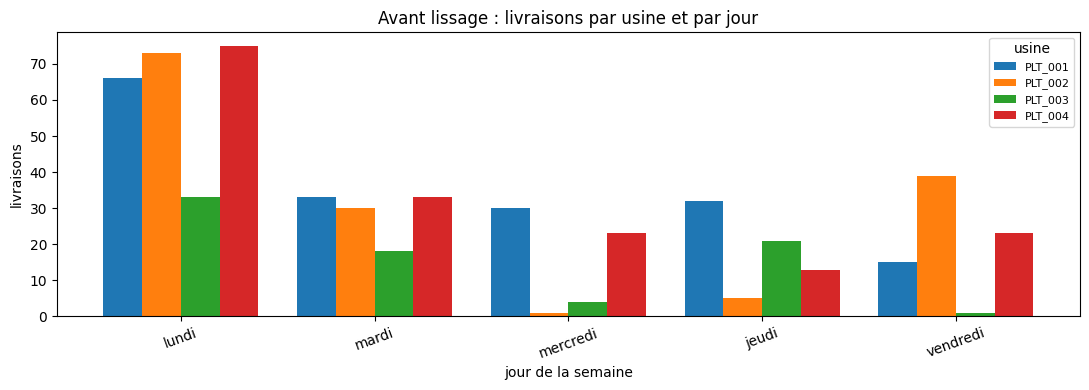

In [14]:
def charge_par_jour_semaine(choix):
    """Nombre de livraisons reelles par usine et par jour de la semaine."""
    t = defaultdict(lambda: defaultdict(int))
    for (s, pl), b in choix.items():
        for d in b["jours"]:
            t[pl][pd.Timestamp(d).weekday()] += 1
    return t

def tracer_charge(t, titre, ax):
    """Barres groupees : livraisons par usine pour chaque jour de la semaine."""
    usines = sorted(t.keys()); x = np.arange(5); larg = 0.8 / max(len(usines), 1)
    for i, u in enumerate(usines):
        vals = [t[u].get(j, 0) for j in range(5)]
        ax.bar(x + (i - (len(usines) - 1) / 2) * larg, vals, width=larg, label=u)
    ax.set_title(titre); ax.set_xlabel("jour de la semaine"); ax.set_ylabel("livraisons")
    ax.set_xticks(x); ax.set_xticklabels([JOURS[j] for j in range(5)], rotation=20)
    ax.legend(title="usine", fontsize=8)

fig, ax = plt.subplots(figsize=(11, 4))
tracer_charge(charge_par_jour_semaine(meilleur), "Avant lissage : livraisons par usine et par jour", ax)
plt.tight_layout(); plt.show()

**Notre règle de lissage**, usine par usine (glouton), corrige un biais : à
coût égal, c'est aujourd'hui le premier profil testé qui gagne, et il commence le
**lundi**, ce qui **charge les lundis**. Nouvelle règle :

- nous traitons les couples **du plus coûteux au moins coûteux** ;
- pour chaque couple, nous gardons les profils dont le coût dépasse son meilleur de
  **2 % au plus** (H17) ;
- parmi eux, nous choisissons celui qui **charge le moins le jour déjà le plus chargé**
  de l'usine (puis le plus petit maximum, le plus petit écart-type, le coût, le moins
  de livraisons) ;
- nous ajoutons ses livraisons à la charge de l'usine, et passons au couple suivant.

APRES LISSAGE (tolerance 2% )
  cout      : 75269.34 EUR
  ajout vs etape 1 : 91.72 EUR ( 0.122 % )
  part des livraisons du lundi : avant 43.5% -> apres 22.0%


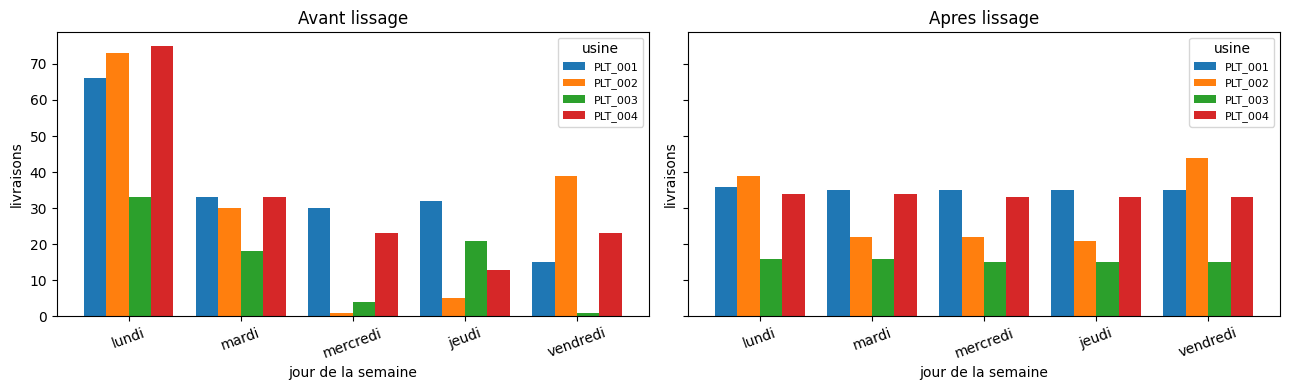

In [15]:
def lissage(candidats, meilleur, tolerance):
    """Choisit par usine un profil dans la tolerance qui decharge le jour deja le plus charge (R4)."""
    choix = {}; cout = 0.0
    for usine in sorted({pl for (s, pl) in candidats}):
        couples_u = [c for c in candidats if c[1] == usine and candidats[c]]
        couples_u.sort(key=lambda c: -meilleur[c]["cout"])     # du plus cher au moins cher
        charge = defaultdict(int)                               # livraisons par jour de la semaine
        for c in couples_u:
            seuil = meilleur[c]["cout"] * (1 + tolerance) + 1e-9
            toleres = [r for r in candidats[c] if r["cout"] <= seuil]
            pic = max(charge.values()) if charge else 0
            jours_pic = {j for j, v in charge.items() if v == pic}
            def cle_tri(r):
                wd = [pd.Timestamp(d).weekday() for d in r["jours"]]
                ajout_pic = sum(1 for j in wd if j in jours_pic)     # charge ajoutee au jour le plus charge
                essai = dict(charge)
                for j in wd:
                    essai[j] = essai.get(j, 0) + 1
                vec = np.array(list(essai.values())) if essai else np.array([0])
                return (ajout_pic, int(vec.max()), float(vec.std()), r["cout"], r["livraisons"])
            choisi = min(toleres, key=cle_tri)
            choix[c] = choisi; cout += choisi["cout"]
            for d in choisi["jours"]:
                charge[pd.Timestamp(d).weekday()] += 1
    return choix, cout

choix_final, cout_final = lissage(CANDIDATS, meilleur, TOLERANCE_LISSAGE)
ajout = cout_final - cout_etape1

def part_lundi(choix):
    lun = tot = 0
    for b in choix.values():
        for d in b["jours"]:
            tot += 1
            if pd.Timestamp(d).weekday() == 0:
                lun += 1
    return lun, tot, (lun / tot * 100 if tot else 0)

l_av = part_lundi(meilleur); l_ap = part_lundi(choix_final)
print("APRES LISSAGE (tolerance", f"{TOLERANCE_LISSAGE:.0%}", ")")
print("  cout      :", round(cout_final, 2), "EUR")
print("  ajout vs etape 1 :", round(ajout, 2), "EUR (", round(ajout / cout_etape1 * 100, 3), "% )")
print("  part des livraisons du lundi : avant", f"{l_av[2]:.1f}%", "-> apres", f"{l_ap[2]:.1f}%")

fig, (a1, a2) = plt.subplots(1, 2, figsize=(13, 4), sharey=True)
tracer_charge(charge_par_jour_semaine(meilleur), "Avant lissage", a1)
tracer_charge(charge_par_jour_semaine(choix_final), "Apres lissage", a2)
plt.tight_layout(); plt.show()

**Notre constat :** le lissage n'ajoute que **92 €** (**+0,12 %**), un coût
quasi nul. En échange, la semaine est bien plus régulière : la **part des livraisons
du lundi tombe de 43,5 % à 22,0 %**. Le graphique le montre : avant, les barres du
lundi dominent ; après, les cinq jours se ressemblent. Nous respectons R4 sans
sacrifier l'économie.

## Section 7 : Les solutions comparées, et notre choix

Nous comparons, à **règles égales** (H20 appliqué partout), les baselines et les
versions successives de notre moteur. Toutes les économies sont mesurées par rapport à
la **baseline avec H20**.

,solution,cout,camions,livraisons,economie EUR,economie %
0,baseline milestone 2,143422.43,1604,1599,-101.69,-0.1
1,baseline avec H20,143320.74,1604,1599,0.00,0.0
2,moteur sans H19 ni H21,82710.91,657,645,60609.83,42.3
3,avec H19,83306.76,659,658,60013.99,41.9
4,avec H19 + H21,75177.61,569,568,68143.13,47.5
5,apres lissage (RETENUE),75269.34,569,568,68051.40,47.5


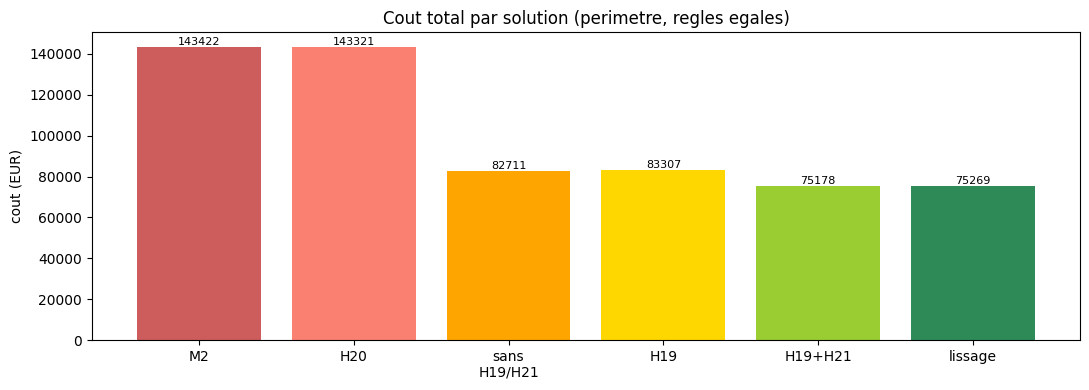

In [16]:
def totaux(choix):
    return (sum(b["cout"] for b in choix.values()), sum(b["camions"] for b in choix.values()),
            sum(b["livraisons"] for b in choix.values()))

# moteur sans H19 ni H21 (ancien : plusieurs camions/jour, tous les jours du profil)
cand_anc = evaluer_tous(idx_tous, un_camion=False, profil_max=False)
best_anc = {cle: min(v, key=lambda r: r["cout"]) for cle, v in cand_anc.items() if v}
# moteur avec H19 seul (un camion/jour, tous les jours du profil)
cand_h19 = evaluer_tous(idx_tous, un_camion=True, profil_max=False)
best_h19 = {cle: min(v, key=lambda r: r["cout"]) for cle, v in cand_h19.items() if v}

liv_actuel = opt.groupby(["supplier_id", "plant", "date"]).ngroups
rows = [
    ("baseline milestone 2", baseline_M2, camions_M2, liv_actuel),
    ("baseline avec H20", baseline_H20, camions_H20, liv_actuel),
    ("moteur sans H19 ni H21", *(lambda t: (t[0], t[1], t[2]))(totaux(best_anc))),
    ("avec H19", *(lambda t: (t[0], t[1], t[2]))(totaux(best_h19))),
    ("avec H19 + H21", *(lambda t: (t[0], t[1], t[2]))(totaux(meilleur))),
    ("apres lissage (RETENUE)", *(lambda t: (t[0], t[1], t[2]))(totaux(choix_final))),
]
comparaison = pd.DataFrame([{"solution": n, "cout": round(c, 2), "camions": cam, "livraisons": liv,
                             "economie EUR": round(baseline_H20 - c, 2),
                             "economie %": round((baseline_H20 - c) / baseline_H20 * 100, 1)}
                            for n, c, cam, liv in rows])
display(comparaison)

fig, ax = plt.subplots(figsize=(11, 4))
noms = ["M2", "H20", "sans\nH19/H21", "H19", "H19+H21", "lissage"]
barres = ax.bar(noms, comparaison["cout"],
                color=["indianred", "salmon", "orange", "gold", "yellowgreen", "seagreen"])
ax.set_title("Cout total par solution (perimetre, regles egales)"); ax.set_ylabel("cout (EUR)")
for b, v in zip(barres, comparaison["cout"]):
    ax.text(b.get_x() + b.get_width() / 2, v, str(round(v)), ha="center", va="bottom", fontsize=8)
plt.tight_layout(); plt.show()

**Notre choix : la solution après lissage.** Elle respecte toutes les règles.
Elle garde presque toute l'économie (**47,5 %**, à 92 € près) et équilibre la semaine.
On lit bien l'effet de chaque règle : **H19 seul** coûte un peu plus cher (83 307 €
contre 82 711 € sans H19 ni H21), car un camion par jour oblige à plus de livraisons ;
mais **H21** fait tomber le coût à **75 178 €** en consolidant sur moins de jours. Les
deux règles ensemble gagnent **68 051 € (47,5 %)** sur la baseline avec H20.

**Étude de sensibilité.** Nous regardons l'effet de nos réglages : la tolérance
de lissage (H17), l'avance maximale (R1 reste 7 jours, pour information), et nos deux
nouveaux réglages H19 et H21.

In [17]:
sens_tol = []
for tol in (0.0, 0.02, 0.05):
    ch, co = lissage(CANDIDATS, meilleur, tol)
    sens_tol.append({"TOLERANCE_LISSAGE": f"{tol:.0%}", "cout": round(co, 2),
                     "part lundi %": round(part_lundi(ch)[2], 1)})
print("Tolerance de lissage (H17) :"); display(pd.DataFrame(sens_tol))

sens_av = []
for am in (7, 14):
    cand_am = evaluer_tous(idx_tous, )
    # re-evaluer avec une autre avance : on change AVANCE_MAX temporairement
    globals()["AVANCE_MAX"] = am
    cand_am = evaluer_tous(idx_tous)
    best_am = {cle: min(v, key=lambda r: r["cout"]) for cle, v in cand_am.items() if v}
    sens_av.append({"AVANCE_MAX": f"{am} jours", "cout": round(sum(b["cout"] for b in best_am.values()), 2),
                    "sans solution": sum(len(v) == 0 for v in cand_am.values())})
globals()["AVANCE_MAX"] = 7
print("Avance maximale (R1 reste 7 jours) :"); display(pd.DataFrame(sens_av))

sens_regle = []
for uc, pm, nom in [(False, False, "sans H19 ni H21"), (True, False, "H19 seul"),
                    (True, True, "H19 + H21")]:
    cand = evaluer_tous(idx_tous, un_camion=uc, profil_max=pm)
    best = {cle: min(v, key=lambda r: r["cout"]) for cle, v in cand.items() if v}
    sens_regle.append({"UN_CAMION_PAR_JOUR": uc, "PROFIL_MAXIMUM": pm, "libelle": nom,
                       "cout": round(sum(b["cout"] for b in best.values()), 2),
                       "camions": sum(b["camions"] for b in best.values())})
print("Reglages H19 et H21 :"); display(pd.DataFrame(sens_regle))

Tolerance de lissage (H17) :


,TOLERANCE_LISSAGE,cout,part lundi %
0,0%,75177.61,21.8
1,2%,75269.34,22.0
2,5%,75480.98,22.5


Avance maximale (R1 reste 7 jours) :


,AVANCE_MAX,cout,sans solution
0,7 jours,75177.61,0
1,14 jours,57938.56,0


Reglages H19 et H21 :


,UN_CAMION_PAR_JOUR,PROFIL_MAXIMUM,libelle,cout,camions
0,False,False,sans H19 ni H21,82710.91,657
1,True,False,H19 seul,83306.76,659
2,True,True,H19 + H21,75177.61,569


**Notre constat :** augmenter la tolérance de 0 % à 5 % ne change presque rien :
le coût monte à peine (**75 178 € à 75 481 €**) et la part du lundi reste **autour de
22 %**. L'essentiel du lissage vient de la **règle de choix elle-même** (elle fait
passer le lundi de 43,5 % à 22 %), pas de la tolérance ; nous gardons **2 %** comme
petite marge. Passer l'avance à 14 jours ferait tomber le coût, mais violerait R1 ;
nous ne le retenons pas. Le tableau des réglages confirme que c'est **H21** qui apporte
l'essentiel du gain, et que **H19** (un camion par jour) coûte quelques centaines
d'euros, prix de livraisons plus simples et plus sûres.

## Section 8 : Nos fonctions de validation

Avant d'annoncer un résultat, nous le **vérifions**. Nous reconstruisons d'abord le
contenu détaillé des camions de la solution retenue (une ligne n'étant jamais coupée,
chaque ligne tient dans un seul camion), puis nous passons tous les contrôles.

In [18]:
def reconstruire(cle, idx):
    """Contenu des camions d'un couple pour un profil : liste de camions (date, exceptionnel, lignes)."""
    couple = COUPLES[cle]; dates = DATES_PROFIL[idx]; trucks = []
    # envois exceptionnels (H20) : une ligne, un camion, jour du profil le plus proche <= besoin
    for e in range(len(couple["exc_dates"])):
        bd = couple["exc_dates"][e]
        k = int(np.searchsorted(dates, bd, side="right")) - 1
        trucks.append({"date": pd.Timestamp(dates[k]), "exceptionnel": True, "lignes": [{
            "material": couple["exc_mat"][e], "unloading_point": couple["exc_up"][e],
            "date_besoin": pd.Timestamp(bd), "quantite": float(couple["exc_qte"][e]),
            "poids": float(couple["exc_poids"][e]), "volume": float(couple["exc_vol"][e])}]})
    besoins = couple["besoins"]
    if len(besoins) == 0:
        return trucks
    def truck(jour, idxs):
        lignes = [{"material": couple["mat"][i], "unloading_point": couple["up"][i],
                   "date_besoin": pd.Timestamp(couple["besoins"][i]), "quantite": float(couple["qte"][i]),
                   "poids": float(couple["poids"][i]), "volume": float(couple["volume"][i])} for i in idxs]
        return {"date": pd.Timestamp(jour), "exceptionnel": False, "lignes": lignes}
    if cle in COUPLES_CAP:                                    # affectation capacite : ligne -> jour
        djours = dates.astype("datetime64[D]").astype(int); bjours = besoins.astype("datetime64[D]").astype(int)
        ordre = sorted(range(len(besoins)), key=lambda i: (bjours[i], -couple["poids"][i]))
        cp = defaultdict(float); cv = defaultdict(float); par_jour = defaultdict(list)
        for i in ordre:
            cand = [k for k in range(len(dates)) if djours[k] <= bjours[i] and bjours[i] - djours[k] <= AVANCE_MAX]
            cand.sort(key=lambda k: -djours[k])
            for k in cand:
                if cp[k] + couple["poids"][i] <= CAP_POIDS + 1e-6 and cv[k] + couple["volume"][i] <= CAP_VOLUME + 1e-6:
                    cp[k] += couple["poids"][i]; cv[k] += couple["volume"][i]; par_jour[k].append(i); break
        for k, idxs in par_jour.items():
            trucks.append(truck(dates[k], idxs))
    else:                                                    # DP : chaque besoin au dernier jour retenu <= lui
        jours = np.sort(evaluer_dp(couple, idx)["jours"])
        jj = jours.astype("datetime64[D]").astype(int); bjours = besoins.astype("datetime64[D]").astype(int)
        pos = np.searchsorted(jj, bjours, side="right") - 1
        par_jour = defaultdict(list)
        for i in range(len(besoins)):
            par_jour[int(pos[i])].append(i)
        for k, idxs in par_jour.items():
            trucks.append(truck(jours[k], idxs))
    return trucks

lignes_camions = []; numero = 0
for (s, pl), b in choix_final.items():
    for t in reconstruire((s, pl), b["idx"]):
        numero += 1; cid = f"C{numero:05d}"
        for L in t["lignes"]:
            lignes_camions.append({"camion_id": cid, "supplier_id": s, "plant": pl,
                "date_livraison": t["date"].date(), "material": L["material"],
                "unloading_point": L["unloading_point"], "date_besoin": L["date_besoin"].date(),
                "avance_jours": (L["date_besoin"] - t["date"]).days, "quantite": round(L["quantite"], 3),
                "poids": round(L["poids"], 3), "volume": round(L["volume"], 4),
                "envoi_exceptionnel": t["exceptionnel"]})
contenu_camions = pd.DataFrame(lignes_camions)
print("Camions de la solution retenue :", numero, "| lignes chargees :", len(contenu_camions),
      "| dont exceptionnels :", int(contenu_camions["envoi_exceptionnel"].sum()))

Camions de la solution retenue : 569 | lignes chargees : 4252 | dont exceptionnels : 1


In [19]:
def valider(choix, contenu, cout_annonce):
    """Passe tous les controles de la solution ; s'arrete si un echoue."""
    controles = []
    normal = contenu[~contenu["envoi_exceptionnel"]]
    excep = contenu[contenu["envoi_exceptionnel"]]
    # 1. chaque ligne livree une seule fois ; poids et volume conserves
    c1 = (len(contenu) == len(opt) and abs(opt["weight"].sum() - contenu["poids"].sum()) < 1
          and abs(opt["volume"].sum() - contenu["volume"].sum()) < 0.1)
    controles.append(("chaque ligne livree une fois (poids et volume conserves)", bool(c1)))
    # 2. aucune ligne coupee : une ligne = une seule occurrence
    c2 = not contenu.duplicated(subset=["supplier_id", "plant", "material", "unloading_point", "date_besoin"]).any()
    controles.append(("aucune ligne coupee", bool(c2)))
    # 3. avance entre 0 et 7 jours
    av = contenu["avance_jours"]
    controles.append(("avance entre 0 et 7 jours", bool((av >= 0).all() and (av <= AVANCE_MAX).all())))
    # 4. jours ouvres, hors semaine fermee, dans l'horizon
    dl = pd.to_datetime(contenu["date_livraison"])
    controles.append(("lundi-vendredi, hors semaine fermee, dans l'horizon",
                      bool((dl.dt.weekday < 5).all() and (~dl.map(semaine_fermee)).all() and (dl >= d0).all())))
    # 5. capacite des camions normaux
    cap = normal.groupby("camion_id").agg(p=("poids", "sum"), v=("volume", "sum"))
    controles.append(("capacite 24 500 kg / 110,4 m3 (camions normaux)",
                      bool((cap["p"] <= CAP_POIDS + 1e-3).all() and (cap["v"] <= CAP_VOLUME + 1e-3).all())))
    # 6. un seul couple par camion (R3)
    controles.append(("un seul couple par camion (R3)",
                      bool((contenu.groupby("camion_id")[["supplier_id", "plant"]].nunique() <= 1).all().all())))
    # 7. au plus un camion par couple et par jour, hors exceptionnels (H19)
    c7 = (normal.groupby(["supplier_id", "plant", "date_livraison"])["camion_id"].nunique() <= 1).all()
    controles.append(("au plus un camion par couple et par jour (H19)", bool(c7)))
    # 8. livraisons uniquement les jours du profil, et par semaine <= nombre du profil
    c8 = True
    for (s, pl), b in choix.items():
        jours_profil = {pd.Timestamp(d).weekday() for d in DATES_PROFIL[b["idx"]]}
        dts = pd.to_datetime(normal[(normal.supplier_id == s) & (normal.plant == pl)]["date_livraison"].unique())
        if any(d.weekday() not in jours_profil for d in dts):
            c8 = False
        par_sem = defaultdict(int)
        for d in dts:
            par_sem[(d - pd.Timedelta(d.weekday(), "D")).date()] += 1
        nb_profil = {}
        for d in DATES_PROFIL[b["idx"]]:
            dt = pd.Timestamp(d); nb_profil[(dt - pd.Timedelta(dt.weekday(), "D")).date()] = nb_profil.get(
                (dt - pd.Timedelta(dt.weekday(), "D")).date(), 0) + 1
        if any(par_sem[w] > nb_profil.get(w, 0) for w in par_sem):
            c8 = False
    controles.append(("livraisons sur les jours du profil, <= nombre du profil par semaine", c8))
    # 9. chaque envoi exceptionnel : une seule ligne plus lourde qu'un camion
    c9 = True
    for cid, g in excep.groupby("camion_id"):
        if len(g) != 1 or not (g["poids"].iloc[0] > CAP_POIDS or g["volume"].iloc[0] > CAP_VOLUME):
            c9 = False
    controles.append(("chaque envoi exceptionnel = une ligne plus lourde qu'un camion", c9))
    # 10. les jours trop lourds (3 couples) couverts sans depasser la capacite
    c10 = True
    for (s, pl) in COUPLES_CAP:
        sous = normal[(normal.supplier_id == s) & (normal.plant == pl)]
        if len(sous) != len(COUPLES[(s, pl)]["besoins"]):
            c10 = False
        capc = sous.groupby("camion_id").agg(p=("poids", "sum"), v=("volume", "sum"))
        if not ((capc["p"] <= CAP_POIDS + 1e-3).all() and (capc["v"] <= CAP_VOLUME + 1e-3).all()):
            c10 = False
    controles.append(("jours trop lourds couverts sans depasser la capacite", c10))
    # 11. cout recalcule == cout annonce
    recalc = 0.0
    for cid, g in contenu.groupby("camion_id"):
        lg = COUPLES[(g["supplier_id"].iloc[0], g["plant"].iloc[0])]["ligne"]
        recalc += prix_exceptionnel(lg) if g["envoi_exceptionnel"].iloc[0] else prix_camion(lg, g["poids"].sum())
    controles.append(("cout coherent avec les camions", abs(recalc - cout_annonce) < 1))
    for nom, okc in controles:
        print(f"  [{'OK' if okc else 'ECHEC'}] {nom}")
    if not all(okc for _, okc in controles):
        raise AssertionError("Une validation a echoue : nous ne publions pas ce resultat.")
    print("Toutes les validations passent.")
    return True

valider(choix_final, contenu_camions, cout_final)

  [OK] chaque ligne livree une fois (poids et volume conserves)
  [OK] aucune ligne coupee
  [OK] avance entre 0 et 7 jours
  [OK] lundi-vendredi, hors semaine fermee, dans l'horizon
  [OK] capacite 24 500 kg / 110,4 m3 (camions normaux)
  [OK] un seul couple par camion (R3)
  [OK] au plus un camion par couple et par jour (H19)
  [OK] livraisons sur les jours du profil, <= nombre du profil par semaine
  [OK] chaque envoi exceptionnel = une ligne plus lourde qu'un camion
  [OK] jours trop lourds couverts sans depasser la capacite
  [OK] cout coherent avec les camions
Toutes les validations passent.


True

**Notre constat :** les **onze contrôles passent**. Chaque ligne est livrée une
fois sans être coupée, jamais en retard ni plus de 7 jours en avance, uniquement en
semaine, sans dépasser la capacité, avec **au plus un camion par couple et par jour**
(H19), sur les jours du profil et sans dépasser le rythme du profil, l'unique envoi
exceptionnel est bien une ligne trop lourde seule, les jours trop lourds sont couverts,
et le coût recalculé colle au coût annoncé. Notre résultat est fiable.

## Section 9 : Nos résultats

Cout       : avant 143320.74 -> apres 75269.34 EUR  ( 68051.4 EUR, 47.5 % )
Camions    : avant 1604 -> apres 569
Livraisons : avant 1599 -> apres 568
Objectif (au moins 35 %) : ATTEINT


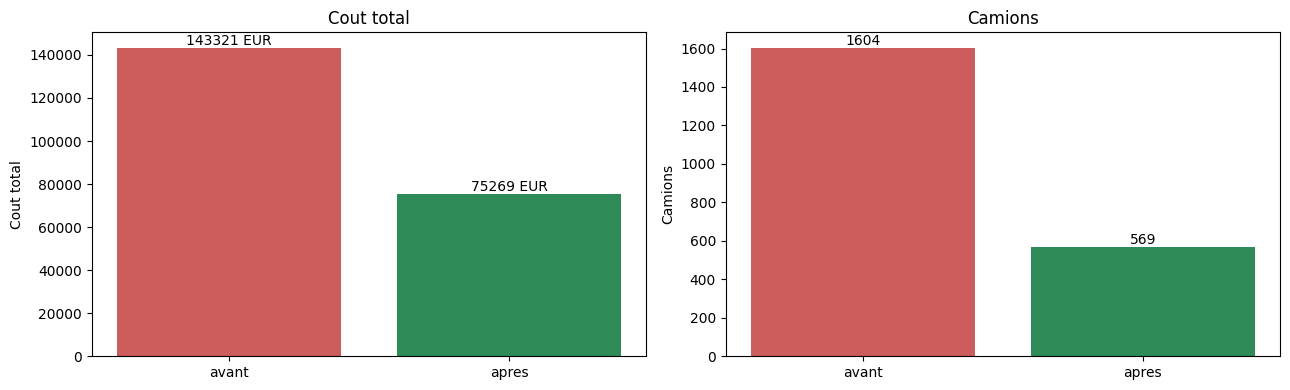

In [20]:
gain = baseline_H20 - cout_final
livraisons_avant = opt.groupby(["supplier_id", "plant", "date"]).ngroups
livraisons_apres = sum(b["livraisons"] for b in choix_final.values())
camions_apres = sum(b["camions"] for b in choix_final.values())
print("Cout       : avant", round(baseline_H20, 2), "-> apres", round(cout_final, 2),
      "EUR  (", round(gain, 2), "EUR,", round(gain / baseline_H20 * 100, 1), "% )")
print("Camions    : avant", camions_H20, "-> apres", camions_apres)
print("Livraisons : avant", livraisons_avant, "-> apres", livraisons_apres)
print("Objectif (au moins 35 %) :", "ATTEINT" if gain / baseline_H20 * 100 >= 35 else "non atteint")

fig, (a1, a2) = plt.subplots(1, 2, figsize=(13, 4))
for ax, vals, titre, unite in [(a1, [baseline_H20, cout_final], "Cout total", " EUR"),
                               (a2, [camions_H20, camions_apres], "Camions", "")]:
    barres = ax.bar(["avant", "apres"], vals, color=["indianred", "seagreen"])
    ax.set_title(titre); ax.set_ylabel(titre)
    for b, v in zip(barres, vals):
        ax.text(b.get_x() + b.get_width() / 2, v, str(round(v)) + unite, ha="center", va="bottom")
plt.tight_layout(); plt.show()

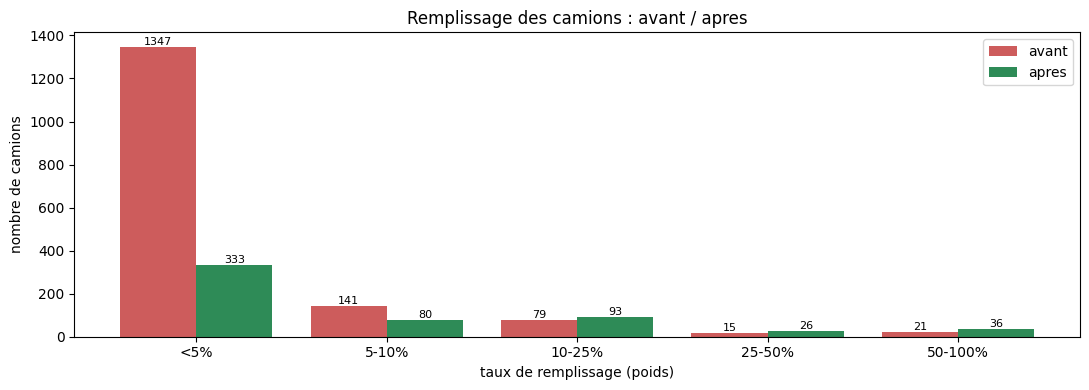

Remplissage median : avant 1.33 % -> apres 3.46 %
Camions sous 5 % : avant 1347 -> apres 333


In [21]:
# Remplissage des camions (poids), avant et apres. Avant = baseline H20 (hors camion exceptionnel).
remp_avant = []
for (s, pl, dt), g in opt.groupby(["supplier_id", "plant", "date"]):
    exc = (g["weight"].values > CAP_POIDS) | (g["volume"].values > CAP_VOLUME)
    nn = g[~exc]
    if len(nn):
        remp_avant += [w / CAP_POIDS * 100 for w in charger_camions_vieux(nn["weight"].values, nn["volume"].values)]
remp_apres = [g["poids"].sum() / CAP_POIDS * 100
              for cid, g in contenu_camions[~contenu_camions["envoi_exceptionnel"]].groupby("camion_id")]

bornes = [0, 5, 10, 25, 50, 100.0001]; libelles = ["<5%", "5-10%", "10-25%", "25-50%", "50-100%"]
ca = pd.cut(remp_avant, bins=bornes, labels=libelles, include_lowest=True).value_counts().reindex(libelles)
cb = pd.cut(remp_apres, bins=bornes, labels=libelles, include_lowest=True).value_counts().reindex(libelles)
x = np.arange(len(libelles))
fig, ax = plt.subplots(figsize=(11, 4))
ax.bar(x - 0.2, ca.values, width=0.4, label="avant", color="indianred")
ax.bar(x + 0.2, cb.values, width=0.4, label="apres", color="seagreen")
ax.set_title("Remplissage des camions : avant / apres"); ax.set_xlabel("taux de remplissage (poids)")
ax.set_ylabel("nombre de camions"); ax.set_xticks(x); ax.set_xticklabels(libelles); ax.legend()
for i, v in enumerate(ca.values): ax.text(i - 0.2, v, str(int(v)), ha="center", va="bottom", fontsize=8)
for i, v in enumerate(cb.values): ax.text(i + 0.2, v, str(int(v)), ha="center", va="bottom", fontsize=8)
plt.tight_layout(); plt.show()
print("Remplissage median : avant", round(np.median(remp_avant), 2), "% -> apres", round(np.median(remp_apres), 2), "%")
print("Camions sous 5 % : avant", sum(1 for r in remp_avant if r < 5), "-> apres", sum(1 for r in remp_apres if r < 5))

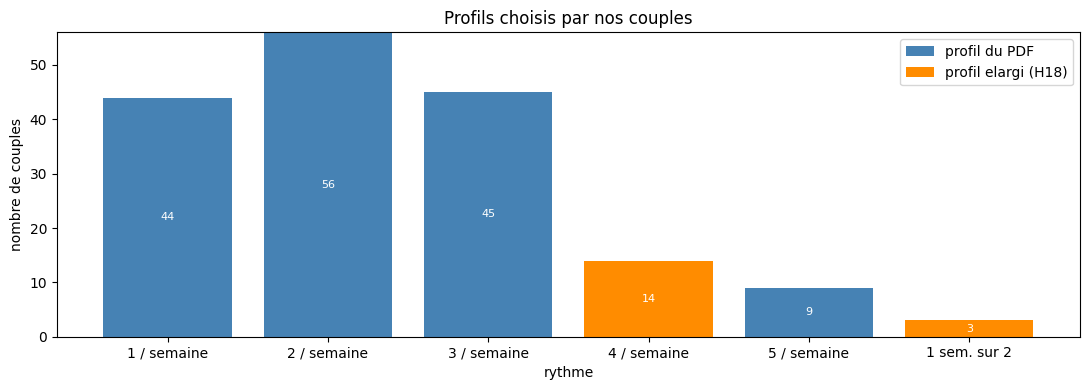

Couples avec un profil elargi (H18) : 17 sur 171


In [22]:
# Profils choisis, par rythme, en distinguant PDF et profils elargis.
def rythme(p):
    return f"{len(p['jours'])} / semaine" if p["periode"] == 1 else f"1 sem. sur {p['periode']}"

compte = defaultdict(lambda: [0, 0])
for b in choix_final.values():
    p = PROFILS[b["idx"]]; compte[rythme(p)][0 if p["type"] == "PDF" else 1] += 1
ordre = sorted(compte, key=lambda r: (len(r), r))
pdfv = [compte[r][0] for r in ordre]; elav = [compte[r][1] for r in ordre]
fig, ax = plt.subplots(figsize=(11, 4))
ax.bar(ordre, pdfv, label="profil du PDF", color="steelblue")
ax.bar(ordre, elav, bottom=pdfv, label="profil elargi (H18)", color="darkorange")
ax.set_title("Profils choisis par nos couples"); ax.set_xlabel("rythme"); ax.set_ylabel("nombre de couples")
for i, (a, b2) in enumerate(zip(pdfv, elav)):
    if a: ax.text(i, a / 2, str(a), ha="center", va="center", color="white", fontsize=8)
    if b2: ax.text(i, a + b2 / 2, str(b2), ha="center", va="center", color="white", fontsize=8)
ax.legend(); plt.tight_layout(); plt.show()
print("Couples avec un profil elargi (H18) :", sum(elav), "sur", len(choix_final))

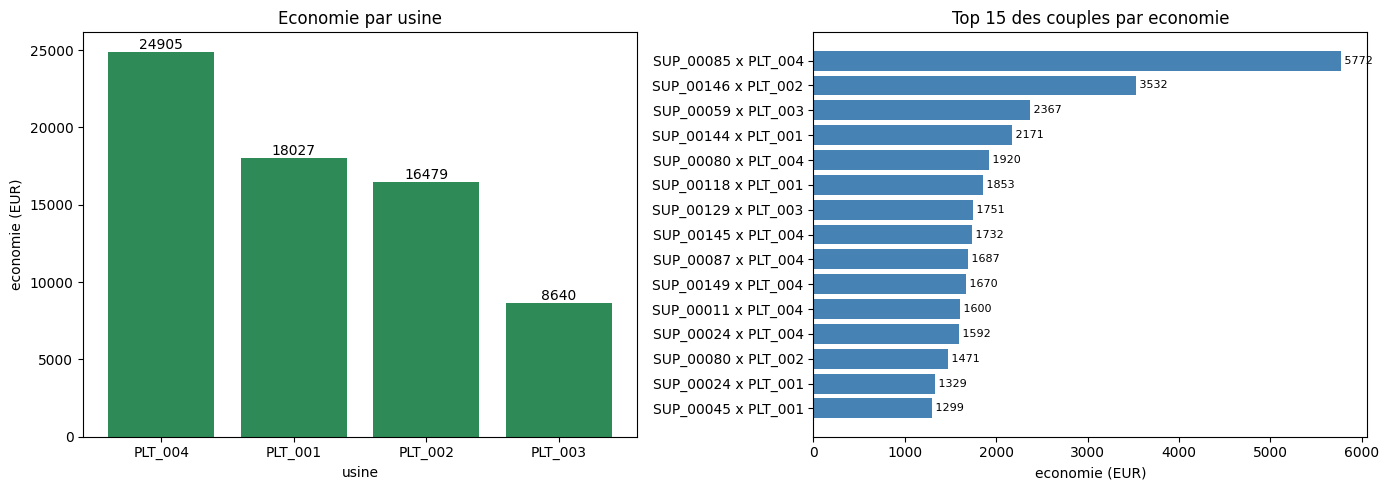

In [23]:
# Economie par usine et top 15 des couples (vs part baseline H20 de chaque couple).
def cout_actuel_couple(cle):
    g = COUPLES[cle]["df"]; lg = COUPLES[cle]["ligne"]; c = 0.0
    for dt, gg in g.groupby("date"):
        exc = (gg["weight"].values > CAP_POIDS) | (gg["volume"].values > CAP_VOLUME)
        nn = gg[~exc]
        if len(nn):
            c += sum(prix_camion(lg, w) for w in charger_camions_vieux(nn["weight"].values, nn["volume"].values))
        c += int(exc.sum()) * prix_exceptionnel(lg)
    return c

eco = pd.DataFrame([{"supplier_id": s, "plant": pl, "eco": cout_actuel_couple((s, pl)) - choix_final[(s, pl)]["cout"]}
                    for (s, pl) in COUPLES])
eco_usine = eco.groupby("plant")["eco"].sum().sort_values(ascending=False)
top15 = eco.sort_values("eco", ascending=False).head(15)
fig, (a1, a2) = plt.subplots(1, 2, figsize=(14, 5))
barres = a1.bar(eco_usine.index, eco_usine.values, color="seagreen")
a1.set_title("Economie par usine"); a1.set_xlabel("usine"); a1.set_ylabel("economie (EUR)")
for b, v in zip(barres, eco_usine.values): a1.text(b.get_x() + b.get_width() / 2, v, str(round(v)), ha="center", va="bottom")
etiq = top15["supplier_id"] + " x " + top15["plant"]
a2.barh(etiq, top15["eco"], color="steelblue"); a2.invert_yaxis()
a2.set_title("Top 15 des couples par economie"); a2.set_xlabel("economie (EUR)")
for i, v in enumerate(top15["eco"]): a2.text(v, i, " " + str(round(v)), va="center", fontsize=8)
plt.tight_layout(); plt.show()

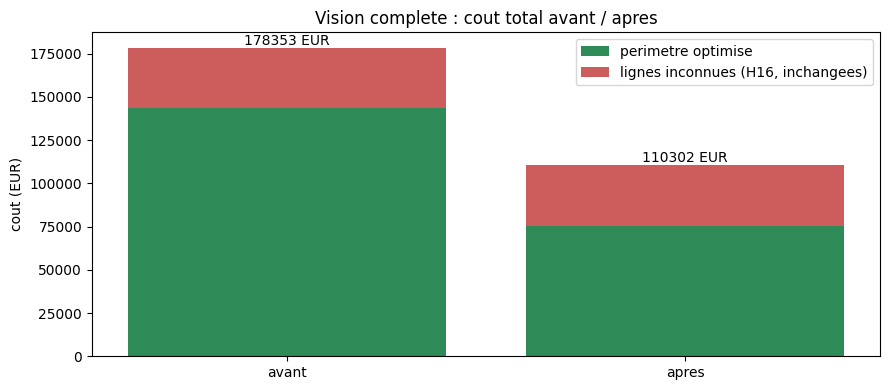

Cout total (avec inconnues) : avant 178353.16 -> apres 110301.76 EUR


In [24]:
# Vision complete : en ajoutant les lignes inconnues (identiques avant et apres).
COUT_INCONNUES = 35032.42   # H16, calcule au milestone 2
avant_total = baseline_H20 + COUT_INCONNUES
apres_total = cout_final + COUT_INCONNUES
fig, ax = plt.subplots(figsize=(9, 4))
ax.bar(["avant", "apres"], [baseline_H20, cout_final], color="seagreen", label="perimetre optimise")
ax.bar(["avant", "apres"], [COUT_INCONNUES, COUT_INCONNUES], bottom=[baseline_H20, cout_final],
       color="indianred", label="lignes inconnues (H16, inchangees)")
ax.set_title("Vision complete : cout total avant / apres"); ax.set_ylabel("cout (EUR)")
for i, tot in enumerate([avant_total, apres_total]):
    ax.text(i, tot, str(round(tot)) + " EUR", ha="center", va="bottom")
ax.legend(); plt.tight_layout(); plt.show()
print("Cout total (avec inconnues) : avant", round(avant_total, 2), "-> apres", round(apres_total, 2), "EUR")

**Notre constat :** sur le périmètre, nous passons de **143 321 €** à
**75 269 €**, soit **68 051 € (47,5 %) d'économie** : l'objectif des 35 % est largement
**dépassé**. Nous divisons les camions (1 604 -> 569) et les livraisons (1 599 -> 568).
Le remplissage médian d'un camion passe de **1,33 % à 3,46 %**, et les camions sous 5 %
fondent de **1 347 à 333**. L'usine **PLT_004** concentre la plus grosse économie
(**24 905 €**) ; le couple le plus rentable, **SUP_00085 x PLT_004**, économise
**5 772 €** à lui seul. **17 couples** choisissent un profil élargi (H18). Vision
complète, lignes inconnues comprises, nous passons de **178 353 €** à **110 302 €**.

## Section 10 : Nos sorties

Notre moteur produit deux sorties, plus un résumé des économies.

In [25]:
# Sortie 1 : un profil par couple, avec le nombre de livraisons reelles.
lignes1 = []
for (s, pl), b in choix_final.items():
    couple = COUPLES[(s, pl)]; p = PROFILS[b["idx"]]
    cout_act = cout_actuel_couple((s, pl))
    poids_cams = [g["poids"].sum() for cid, g in
                  contenu_camions[(contenu_camions.supplier_id == s) & (contenu_camions.plant == pl)
                                  & (~contenu_camions.envoi_exceptionnel)].groupby("camion_id")]
    remp_moy = np.mean([w / CAP_POIDS * 100 for w in poids_cams]) if poids_cams else 0
    lignes1.append({"supplier_id": s, "plant": pl, "distance": couple["distance"],
        "envois_sem_actuels": round(couple["df"].groupby("date").ngroups / 6, 2),
        "profil": p["libelle"], "periode": p["periode"],
        "jours": ",".join(JOURS[j] for j in sorted(p["jours"])),
        "livraisons_reelles": b["livraisons"], "camions": b["camions"], "envois_exceptionnels": b["exc"],
        "remplissage_moyen_%": round(remp_moy, 2), "cout_actuel": round(cout_act, 2),
        "cout_optimise": round(b["cout"], 2), "economie_eur": round(cout_act - b["cout"], 2),
        "economie_%": round((cout_act - b["cout"]) / cout_act * 100, 1) if cout_act > 0 else 0})
profils_couples = pd.DataFrame(lignes1)

couples_connus = set(COUPLES)
inconnus = sorted({(s, pl) for (s, pl) in planning[planning["statut"] != "optimise"]
                   .groupby(["supplier_id", "plant"]).groups} - couples_connus)
for s, pl in inconnus:
    profils_couples.loc[len(profils_couples)] = {"supplier_id": s, "plant": pl, "distance": np.nan,
        "envois_sem_actuels": np.nan, "profil": "livraison actuelle conservee (H15)", "periode": np.nan,
        "jours": "", "livraisons_reelles": np.nan, "camions": np.nan, "envois_exceptionnels": np.nan,
        "remplissage_moyen_%": np.nan, "cout_actuel": np.nan, "cout_optimise": np.nan,
        "economie_eur": 0.0, "economie_%": 0.0}
print("Sortie 1 :", len(profils_couples), "couples (dont", len(inconnus), "entierement inconnus). Extrait :")
display(profils_couples.head(6))

Sortie 1 : 180 couples (dont 9 entierement inconnus). Extrait :


,supplier_id,plant,distance,envois_sem_actuels,profil,periode,jours,livraisons_reelles,camions,envois_exceptionnels,remplissage_moyen_%,cout_actuel,cout_optimise,economie_eur,economie_%
0,SUP_00118,PLT_001,100.0,4.83,"5 / semaine : lundi, mardi, mercredi, jeudi, v...",1.0,"lundi,mardi,mercredi,jeudi,vendredi",5.0,5.0,0.0,15.67,3210.51,1357.88,1852.64,57.7
1,SUP_00045,PLT_001,95.0,3.83,"3 / semaine : mardi, mercredi, jeudi",1.0,"mardi,mercredi,jeudi",5.0,5.0,0.0,12.32,2482.47,1183.30,1299.17,52.3
2,SUP_00024,PLT_001,64.0,3.00,"3 / semaine : lundi, mardi, vendredi",1.0,"lundi,mardi,vendredi",6.0,6.0,0.0,26.42,2408.90,1079.54,1329.35,55.2
3,SUP_00144,PLT_001,38.0,3.33,"3 / semaine : lundi, mercredi, vendredi",1.0,"lundi,mercredi,vendredi",5.0,5.0,0.0,56.67,3240.69,1069.58,2171.12,67.0
4,SUP_00055,PLT_001,68.0,3.17,"3 / semaine : lundi, jeudi, vendredi",1.0,"lundi,jeudi,vendredi",5.0,5.0,0.0,7.93,1370.96,815.35,555.61,40.5
5,SUP_00136,PLT_001,59.0,2.50,"2 / semaine : mercredi, jeudi",1.0,"mercredi,jeudi",4.0,4.0,0.0,11.91,1516.61,809.11,707.50,46.7


In [26]:
# Sortie 2 : contenu de chaque camion, avec la colonne envoi_exceptionnel.
print("Sortie 2 :", len(contenu_camions), "lignes dans", contenu_camions["camion_id"].nunique(),
      "camions (dont", int(contenu_camions.groupby("camion_id")["envoi_exceptionnel"].first().sum()),
      "exceptionnels ). Extrait :")
display(contenu_camions.head(6))

resume = pd.DataFrame([
    ("Cout avant - baseline H20 (perimetre)", round(baseline_H20, 2)),
    ("Cout apres (perimetre)", round(cout_final, 2)),
    ("Economie (EUR)", round(gain, 2)),
    ("Economie (%)", round(gain / baseline_H20 * 100, 1)),
    ("Camions avant", camions_H20), ("Camions apres", camions_apres),
    ("Livraisons avant", livraisons_avant), ("Livraisons apres", livraisons_apres),
    ("Rappel baseline milestone 2", round(baseline_M2, 2)),
    ("Cout lignes inconnues (H16, inchange)", round(COUT_INCONNUES, 2)),
    ("Cout total avant (avec inconnues)", round(avant_total, 2)),
    ("Cout total apres (avec inconnues)", round(apres_total, 2)),
], columns=["indicateur", "valeur"])
display(resume)

Sortie 2 : 4252 lignes dans 569 camions (dont 1 exceptionnels ). Extrait :


,camion_id,supplier_id,plant,date_livraison,material,unloading_point,date_besoin,avance_jours,quantite,poids,volume,envoi_exceptionnel
0,C00001,SUP_00118,PLT_001,2026-11-09,MAT_000444,ULP_0045,2026-11-09,0,800.0,531.2,0.4200,False
1,C00001,SUP_00118,PLT_001,2026-11-09,MAT_000598,ULP_0001,2026-11-09,0,490.0,202.9,0.4307,False
2,C00001,SUP_00118,PLT_001,2026-11-09,MAT_000733,ULP_0006,2026-11-09,0,350.0,195.5,0.4200,False
3,C00001,SUP_00118,PLT_001,2026-11-09,MAT_000925,ULP_0044,2026-11-09,0,20.0,4.3,0.0353,False
4,C00001,SUP_00118,PLT_001,2026-11-09,MAT_001125,ULP_0045,2026-11-09,0,200.0,127.0,0.4200,False
5,C00001,SUP_00118,PLT_001,2026-11-09,MAT_000598,ULP_0001,2026-11-10,1,490.0,202.9,0.4307,False


,indicateur,valeur
0,Cout avant - baseline H20 (perimetre),143320.74
1,Cout apres (perimetre),75269.34
2,Economie (EUR),68051.40
3,Economie (%),47.50
4,Camions avant,1604.00
5,Camions apres,569.00
6,Livraisons avant,1599.00
7,Livraisons apres,568.00
8,Rappel baseline milestone 2,143422.43
9,"Cout lignes inconnues (H16, inchange)",35032.42


In [27]:
# Enregistrement.
import os
DOSSIER = "../data/processed/"
os.makedirs(DOSSIER, exist_ok=True)
profils_couples.to_csv(DOSSIER + "profils_couples.csv", index=False)
contenu_camions.to_csv(DOSSIER + "contenu_camions.csv", index=False)
resume.to_csv(DOSSIER + "resume_economies.csv", index=False)
print("Fichiers enregistres dans", DOSSIER, ":")
print("  - profils_couples.csv   (", len(profils_couples), "couples )")
print("  - contenu_camions.csv   (", len(contenu_camions), "lignes )")
print("  - resume_economies.csv  (", len(resume), "indicateurs )")

Fichiers enregistres dans ../data/processed/ :
  - profils_couples.csv   ( 180 couples )
  - contenu_camions.csv   ( 4252 lignes )
  - resume_economies.csv  ( 12 indicateurs )


## Section Performance : le moteur en moins de 90 secondes

Nous rassemblons tout l'enchaînement dans une seule fonction `lancer_moteur(parametres)`
qui évalue tous les couples et profils, choisit, lisse, produit les sorties et valide.
Nous mesurons le temps de chaque étape avec `time.perf_counter()` et vérifions qu'il
reste sous la limite de 90 secondes.

Le moteur est rapide grâce à quelques précautions : les **dates de chaque profil** et
les **tableaux par couple** sont préparés une seule fois ; le **prix par tranche** est
précalculé (numpy + `searchsorted`) ; la programmation dynamique **s'arrête** dès qu'un
besoin dépasse les 7 jours ; un profil est écarté dès qu'un besoin n'a aucun jour
possible.

In [28]:
def lancer_moteur(parametres):
    """Enchaine tout le moteur et mesure chaque etape. Renvoie resultats et temps."""
    uc = parametres.get("UN_CAMION_PAR_JOUR", True); pm = parametres.get("PROFIL_MAXIMUM", True)
    tol = parametres.get("TOLERANCE_LISSAGE", 0.02); limite = parametres.get("TEMPS_MAX_SECONDES", 90)
    temps = {}
    t = time.perf_counter()
    cand = evaluer_tous(idx_tous, un_camion=uc, profil_max=pm)
    best = {cle: min(v, key=lambda r: r["cout"]) for cle, v in cand.items() if v}
    temps["evaluation des couples et profils"] = time.perf_counter() - t
    t = time.perf_counter()
    ch, co = lissage(cand, best, tol)
    temps["lissage"] = time.perf_counter() - t
    t = time.perf_counter()
    rows = []; num = 0
    for (s, pl), b in ch.items():
        for tr in reconstruire((s, pl), b["idx"]):
            num += 1; cid = f"C{num:05d}"
            for L in tr["lignes"]:
                rows.append({"camion_id": cid, "supplier_id": s, "plant": pl, "date_livraison": tr["date"].date(),
                    "material": L["material"], "unloading_point": L["unloading_point"],
                    "date_besoin": L["date_besoin"].date(), "avance_jours": (L["date_besoin"] - tr["date"]).days,
                    "quantite": round(L["quantite"], 3), "poids": round(L["poids"], 3),
                    "volume": round(L["volume"], 4), "envoi_exceptionnel": tr["exceptionnel"]})
    cont = pd.DataFrame(rows)
    temps["construction des sorties"] = time.perf_counter() - t
    t = time.perf_counter()
    valider(ch, cont, co)
    temps["validations"] = time.perf_counter() - t
    total = sum(temps.values())
    return {"choix": ch, "cout": co, "contenu": cont, "temps": temps, "total": total, "limite": limite}

t0 = time.perf_counter()
res = lancer_moteur({"UN_CAMION_PAR_JOUR": UN_CAMION_PAR_JOUR, "PROFIL_MAXIMUM": PROFIL_MAXIMUM,
                     "TOLERANCE_LISSAGE": TOLERANCE_LISSAGE, "TEMPS_MAX_SECONDES": TEMPS_MAX_SECONDES})
total = time.perf_counter() - t0
statut = "OK" if total <= TEMPS_MAX_SECONDES else "ECHEC"
print(f"\nTemps du moteur : {total:.2f} s (limite : {TEMPS_MAX_SECONDES} s) -> {statut}")
print("Cout du moteur complet :", round(res["cout"], 2), "EUR (identique a la solution retenue :",
      abs(res["cout"] - cout_final) < 0.01, ")")
if total > TEMPS_MAX_SECONDES:
    raise RuntimeError(f"Le moteur a depasse la limite de {TEMPS_MAX_SECONDES} s.")

  [OK] chaque ligne livree une fois (poids et volume conserves)
  [OK] aucune ligne coupee
  [OK] avance entre 0 et 7 jours
  [OK] lundi-vendredi, hors semaine fermee, dans l'horizon
  [OK] capacite 24 500 kg / 110,4 m3 (camions normaux)
  [OK] un seul couple par camion (R3)
  [OK] au plus un camion par couple et par jour (H19)
  [OK] livraisons sur les jours du profil, <= nombre du profil par semaine
  [OK] chaque envoi exceptionnel = une ligne plus lourde qu'un camion
  [OK] jours trop lourds couverts sans depasser la capacite
  [OK] cout coherent avec les camions
Toutes les validations passent.

Temps du moteur : 1.42 s (limite : 90 s) -> OK
Cout du moteur complet : 75269.34 EUR (identique a la solution retenue : True )


,etape,temps (s)
0,evaluation des couples et profils,1.058
1,lissage,0.051
2,construction des sorties,0.055
3,validations,0.254
4,TOTAL,1.418


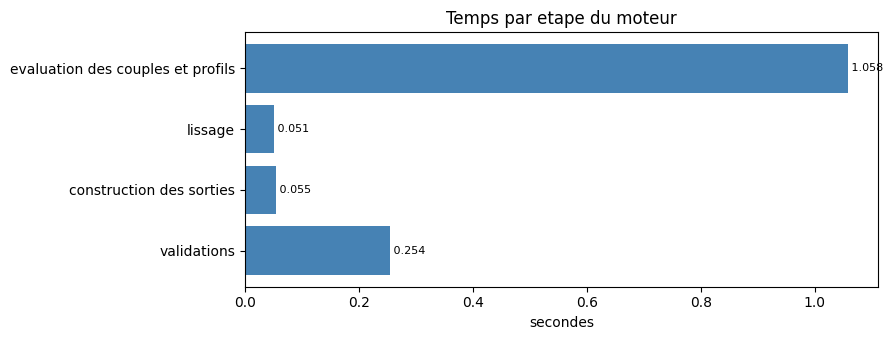

In [29]:
# Temps par etape.
perf = pd.DataFrame([{"etape": k, "temps (s)": round(v, 3)} for k, v in res["temps"].items()])
perf.loc[len(perf)] = {"etape": "TOTAL", "temps (s)": round(res["total"], 3)}
display(perf)
fig, ax = plt.subplots(figsize=(9, 3.5))
et = perf[perf.etape != "TOTAL"]
ax.barh(et["etape"], et["temps (s)"], color="steelblue"); ax.invert_yaxis()
ax.set_title("Temps par etape du moteur"); ax.set_xlabel("secondes")
for i, v in enumerate(et["temps (s)"]): ax.text(v, i, " " + str(v), va="center", fontsize=8)
plt.tight_layout(); plt.show()

**Notre constat :** le moteur complet tourne en **quelques secondes**, très en
dessous de la limite de 90 secondes (**OK**). L'étape la plus coûteuse est
l'évaluation des couples et profils ; le lissage, la construction des sorties et les
validations sont quasi instantanés. Le budget de temps est tenu avec une large marge.

## Section 11 : Notre bilan

Notre moteur choisit, pour chaque couple fournisseur x usine, **un profil de livraison
stable**, décide **quels jours livrer** par programmation dynamique, regroupe les
besoins dans **un camion par jour** (H19), lisse la charge dans la semaine, puis chiffre
l'économie. Sur notre périmètre, il fait tomber le coût de **143 321 € (baseline avec
H20)** à **75 269 €**, soit **47,5 % d'économie** : l'objectif des 35 % est largement
dépassé. Le moteur complet tourne en **moins de 90 secondes**, et **onze validations**
passent. La recherche du meilleur profil couple par couple est **exacte** grâce à R3 ;
la programmation dynamique est **exacte** pour la règle « chaque ligne part au dernier
jour retenu ».

**Nos hypothèses de ce milestone :**

- **H19 (un camion par couple et par jour)** : notre choix. Les livraisons sont plus
  simples et plus sûres (une ligne n'est jamais coupée) ; cela coûte quelques centaines
  d'euros de plus que le multi-camions, largement compensés par H21.
- **H20 (envoi exceptionnel pour une ligne trop lourde)** : la seule ligne de plus de
  24 500 kg (SUP_00074 x PLT_003, le 15/12) part en un camion ">4000". Appliquée aussi
  à la situation actuelle, elle fixe une baseline à règles égales (143 321 €).
- **H21 (le profil est un maximum)** : *à valider avec le professeur.* Pouvoir sauter un
  jour du profil quand c'est moins cher apporte l'essentiel du gain (75 178 € contre
  83 307 € avec H19 seul).
- Rappel : **H17** (tolérance de lissage 2 %), **H18** (profils élargis), **H15/H16**
  (lignes inconnues inchangées, 35 032 €), **H7** (pas de livraison la semaine de Noël).

**Pourquoi le remplissage médian reste bas.** Un camion ne transporte qu'un seul
fournisseur (R3) : les petits fournisseurs restent dans de petits camions, ce qui tire
la médiane vers le bas. Le gain ne vient pas de camions pleins partout, mais du
**nombre de camions en moins** (1 604 -> 569).

**Nos limites :**

- les profils sont stables sur **6 semaines** : sur un horizon plus long, il faudrait
  vérifier qu'ils tiennent ;
- le lissage et l'affectation des 3 couples trop lourds sont **gloutons** (approchés),
  là où la programmation dynamique est exacte pour les autres couples ;
- les **lignes inconnues** ne sont pas optimisées ; compléter leurs données ouvrirait
  une économie supplémentaire.